# Proyek Pembelajaran Mendalam (IF2121)
## Klasifikasi Huruf Bahasa Isyarat Amerika (ASL) pada *Sign Language MNIST* dengan DNN (MLP) dan CNN

**Program Studi Teknik Informatika, Fakultas Informatika, Universitas Mikroskil**
Semester Ganjil · TA 2026–2027 · Kelas IF-A PAGI · Kelompok 1

| NIM | Nama | Peran |
|---|---|---|
| 231111408 | Steven David H Malau | Ketua Tim & Model Engineer (CNN) |
| 231111488 | Wan Saka Nasa | Data Engineer (EDA, Preprocessing, tf.data) |
| 231111207 | Edwin Valentino Tarigan | DNN & Optimasi (Perceptron, MLP, Optimizer) |
| 231110581 | Eric Chandra | Evaluasi & Fitur Unik (Threshold/OOD, TFLite, Grad-CAM) |
| 231111650 | Dhaifan Al Ghani | Deployment & Dokumentasi (Gradio, HF Spaces, GitHub, Video) |

Aplikasi: https://huggingface.co/spaces/superstev/asl-sign-mnist · Repositori: https://github.com/stevbell123/asl-sign-mnist



| Kebutuhan | Bagian notebook |
|---|---|
| Dataset, EDA (distribusi kelas, histogram, korelasi, contoh per kelas) | 1–2 |
| Preprocessing, pembagian data, pencegahan kebocoran data | 3 |
| Tensor & `tf.data` (RTM CPMK 1, langkah 4) | 4–5 |
| Perceptron, MLP/DNN, backpropagation (RTM CPMK 2) | 6 |
| Optimasi & regularisasi: loss, dropout, BN, Adam/RMSProp, LR scheduling, monitoring, early stopping (RTM CPMK 3) | 7–9 |
| CNN (RTM CPMK 4) dan iterasi perbaikan E1–E5 | 8, 10–11 |
| Evaluasi: accuracy, precision, recall, F1, confusion matrix, analisis error | 12 |
| **Fitur unik 1**: confidence threshold + deteksi input di luar domain | 13 |
| **Fitur unik 2**: kompresi model ke TensorFlow Lite | 14 |
| Grad-CAM (interpretasi) | 15 |
| Deployment: aplikasi Gradio untuk Hugging Face Spaces + repositori GitHub | 17 |
| Penyimpanan hasil dan repositori GitHub | 18 |



In [ ]:
# =============================================================================
# KONFIGURASI PROYEK: ubah bagian ini saja
# =============================================================================
NAMA_KELOMPOK = "Kelompok1"
KELAS         = "IF-A-PAGI"
JUDUL = ("Klasifikasi Huruf Bahasa Isyarat Amerika (ASL) pada Dataset Sign Language MNIST "
         "Menggunakan Deep Neural Network dan Convolutional Neural Network")
MATA_KULIAH   = "IF2121 – Pembelajaran Mendalam"
JENIS_LAPORAN = "Ujian Tengah Semester"
SEMESTER      = "Ganjil"
TAHUN_AJARAN  = "2026-2027"


ANGGOTA = [
    {"nama": "Steven David H Malau",    "nim": "231111408", "peran": "Ketua Tim & Model Engineer (CNN)"},
    {"nama": "Wan Saka Nasa",           "nim": "231111488", "peran": "Data Engineer (EDA, Preprocessing, tf.data)"},
    {"nama": "Edwin Valentino Tarigan", "nim": "231111207", "peran": "DNN & Optimasi (Perceptron, MLP, Optimizer)"},
    {"nama": "Eric Chandra",            "nim": "231110581", "peran": "Evaluasi & Fitur Unik (Threshold/OOD, TFLite, Grad-CAM)"},
    {"nama": "Dhaifan Al Ghani",        "nim": "231111650", "peran": "Deployment & Dokumentasi (Gradio, HF Spaces, GitHub, Video)"},
]



LINK_GITHUB = "https://github.com/stevbell123/asl-sign-mnist"
LINK_VIDEO  = ""
LINK_APP    = "https://huggingface.co/spaces/superstev/asl-sign-mnist"
LOGO_PATH   = "logo_mikroskil.png"

SEED        = 42
VAL_SIZE    = 0.10
BATCH_SIZE  = 128
TARGET_ACC_DITERIMA = 0.995
QUICK_MODE  = False
RUN_GRADIO_DEMO = False

In [24]:
# =============================================================================
# 0. SETUP: import library, seed, GPU, dan folder output
# =============================================================================
import os, sys, time, json, glob, shutil, random, subprocess, platform, datetime, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

import tensorflow as tf
import keras
from keras import layers

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

keras.utils.set_random_seed(SEED)          # seed python, numpy, dan TensorFlow sekaligus
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

OUT_DIR   = "outputs"
FIG_DIR   = os.path.join(OUT_DIR, "figures")
MODEL_DIR = os.path.join(OUT_DIR, "models")
LOG_DIR   = os.path.join(OUT_DIR, "logs")
for d in (OUT_DIR, FIG_DIR, MODEL_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

# Penampung seluruh hasil numerik; disimpan ke results.json
R = {"meta": {}, "data": {}, "tensor": {}, "pipeline": {}, "perceptron": {}, "activation": {},
     "optimizer": {}, "experiments": [], "final": {}, "fitur1": {}, "fitur2": {}, "gradcam": {},
     "deploy": {}, "previous": {}, "figures": {}}

def savefig(key, fig=None, caption=None):
    # Simpan figure ke outputs/figures/<key>.png dan catat path-nya di R['figures'].
    fig = fig or plt.gcf()
    path = os.path.join(FIG_DIR, f"{key}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    R["figures"][key] = path
    print(f"[gambar tersimpan] {path}")

gpus = tf.config.list_physical_devices("GPU")
gpu_name = "Tidak ada (CPU)"
if gpus:
    try:
        gpu_name = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU")
    except Exception:
        gpu_name = "GPU"
    for g in gpus:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except Exception:
            pass

R["meta"].update({
    "nama_kelompok": NAMA_KELOMPOK, "kelas": KELAS, "judul": JUDUL, "anggota": ANGGOTA,
    "mata_kuliah": MATA_KULIAH, "jenis_laporan": JENIS_LAPORAN, "semester": SEMESTER, "tahun_ajaran": TAHUN_AJARAN,
    "seed": SEED, "quick_mode": QUICK_MODE, "tanggal": datetime.datetime.now().strftime("%d-%m-%Y %H:%M"),
    "python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
    "numpy": np.__version__, "sklearn": sklearn.__version__, "opencv": cv2.__version__,
    "gpu": gpu_name, "colab": IN_COLAB, "batch_size": BATCH_SIZE, "val_size": VAL_SIZE,
})
T_START = time.time()
print("=" * 64)
for k in ["python", "tensorflow", "keras", "numpy", "sklearn", "opencv", "gpu"]:
    print(f"{k:<11}: {R['meta'][k]}")
print("=" * 64)
if not gpus:
    print("PERINGATAN: GPU tidak terdeteksi. Aktifkan Runtime → Change runtime type → T4 GPU agar training lebih cepat.")

python     : 3.13.16
tensorflow : 2.21.0
keras      : 3.13.2
numpy      : 2.4.6
sklearn    : 1.6.1
opencv     : 4.14.0
gpu        : Tesla T4


## 1. Akuisisi Dataset: Sign Language MNIST
Dataset **Sign Language MNIST** (Datamunge, 2017) berisi citra *grayscale* 28×28 piksel untuk 24 huruf ASL (A–Y tanpa J dan Z karena keduanya memerlukan gerakan). Data latih resmi berjumlah 27.455 citra dan data uji resmi 7.172 citra.

Urutan sumber yang dicoba: (1) berkas CSV lokal di folder `data/`, (2) **KaggleHub**, (3) mirror GitHub, (4) unggah manual. Proyek sebelumnya hanya memakai **1.200 citra** (50/kelas). Versi ini memakai **seluruh data** dan **data uji resmi yang terpisah**.

In [25]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

def find_csv(root, recursive=True):
    pat_tr = os.path.join(root, "**", "sign_mnist_train.csv") if recursive else os.path.join(root, "sign_mnist_train.csv")
    pat_te = os.path.join(root, "**", "sign_mnist_test.csv")  if recursive else os.path.join(root, "sign_mnist_test.csv")
    tr, te = glob.glob(pat_tr, recursive=recursive), glob.glob(pat_te, recursive=recursive)
    return (tr[0], te[0]) if tr and te else (None, None)

train_csv, test_csv = find_csv(DATA_DIR)
sumber = "lokal (folder data/)"
if train_csv is None:
    train_csv, test_csv = find_csv(".", recursive=False)

if train_csv is None:                                   # (2) KaggleHub
    try:
        import kagglehub
        path = kagglehub.dataset_download("datamunge/sign-language-mnist")
        train_csv, test_csv = find_csv(path)
        sumber = "KaggleHub (datamunge/sign-language-mnist)"
    except Exception as e:
        print("KaggleHub tidak tersedia/gagal:", repr(e)[:200])

if train_csv is None:                                   # (3) mirror GitHub
    try:
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/pdthuc/Project-Sign_Language-MNIST.git",
                        os.path.join(DATA_DIR, "mirror")], check=True, capture_output=True, timeout=300)
        train_csv, test_csv = find_csv(DATA_DIR)
        sumber = "mirror GitHub (salinan CSV Kaggle)"
    except Exception as e:
        print("Mirror GitHub gagal:", repr(e)[:200])

if train_csv is None and IN_COLAB:                      # (4) unggah manual
    from google.colab import files
    print("Unggah sign_mnist_train.csv dan sign_mnist_test.csv (atau archive.zip dari Kaggle):")
    for name, content in files.upload().items():
        with open(os.path.join(DATA_DIR, name), "wb") as f:
            f.write(content)
        if name.endswith(".zip"):
            shutil.unpack_archive(os.path.join(DATA_DIR, name), DATA_DIR)
    train_csv, test_csv = find_csv(DATA_DIR)
    sumber = "unggah manual"

assert train_csv is not None, "Dataset tidak ditemukan. Letakkan sign_mnist_train.csv & sign_mnist_test.csv di folder data/."

df_train = pd.read_csv(train_csv)
df_test  = pd.read_csv(test_csv)
print("Sumber data :", sumber)
print("Train CSV   :", df_train.shape, "| Test CSV:", df_test.shape)
assert df_train.shape == (27455, 785) and df_test.shape == (7172, 785), "Ukuran dataset tidak sesuai versi Kaggle."
R["data"]["sumber"] = sumber
df_train.head(3)

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Sumber data : KaggleHub (datamunge/sign-language-mnist)
Train CSV   : (27455, 785) | Test CSV: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195


## 2. Eksplorasi Data (EDA)
Pemeriksaan kualitas data: tipe data, *missing value*, duplikat, distribusi kelas, contoh citra, citra rata-rata per kelas, dan distribusi intensitas piksel data latih dibandingkan data uji.

In [26]:
LABELS_ORIG = sorted(df_train["label"].unique())                     # 0..24 tanpa 9 (J)
CLASS_NAMES = [chr(ord("A") + int(l)) for l in LABELS_ORIG]          # 'A'..'Y' tanpa J, Z
N_CLASSES   = len(CLASS_NAMES)
LABEL_MAP   = {int(o): i for i, o in enumerate(LABELS_ORIG)}         # label asli -> indeks 0..23

pix_cols = [c for c in df_train.columns if c != "label"]
missing_tr, missing_te = int(df_train.isna().sum().sum()), int(df_test.isna().sum().sum())
dup_train = int(df_train.duplicated().sum())
dup_test  = int(df_test.duplicated().sum())
h_tr = set(pd.util.hash_pandas_object(df_train[pix_cols], index=False).values)
h_te = pd.util.hash_pandas_object(df_test[pix_cols], index=False).values
overlap = int(sum(h in h_tr for h in h_te))
rng_ok = df_train[pix_cols].values.min() >= 0 and df_train[pix_cols].values.max() <= 255

print(f"Jumlah kelas            : {N_CLASSES} -> {''.join(CLASS_NAMES)}")
print(f"Tipe data piksel        : {df_train[pix_cols].dtypes.unique()}")
print(f"Missing value train/test: {missing_tr} / {missing_te}")
print(f"Duplikat persis train   : {dup_train} | test: {dup_test}")
print(f"Citra uji yang identik dengan citra latih: {overlap}")
print(f"Rentang piksel valid [0,255]: {rng_ok}")

train_counts = df_train["label"].map(LABEL_MAP).value_counts().sort_index()
test_counts  = df_test["label"].map(LABEL_MAP).value_counts().sort_index()
R["data"].update({
    "n_train_raw": len(df_train), "n_test_raw": len(df_test), "n_classes": N_CLASSES,
    "class_names": CLASS_NAMES, "missing_train": missing_tr, "missing_test": missing_te,
    "dup_train": dup_train, "dup_test": dup_test, "overlap_train_test": overlap,
    "train_counts": {CLASS_NAMES[i]: int(c) for i, c in train_counts.items()},
    "test_counts":  {CLASS_NAMES[i]: int(c) for i, c in test_counts.items()},
    "imbalance_ratio_train": float(train_counts.max() / train_counts.min()),
    "imbalance_ratio_test":  float(test_counts.max() / test_counts.min()),
})
print(f"Rasio kelas terbanyak/tersedikit: train {R['data']['imbalance_ratio_train']:.2f} | test {R['data']['imbalance_ratio_test']:.2f}")

Jumlah kelas            : 24 -> ABCDEFGHIKLMNOPQRSTUVWXY
Tipe data piksel        : [dtype('int64')]
Missing value train/test: 0 / 0
Duplikat persis train   : 0 | test: 0
Citra uji yang identik dengan citra latih: 0
Rentang piksel valid [0,255]: True
Rasio kelas terbanyak/tersedikit: train 1.35 | test 3.46


[gambar tersimpan] outputs/figures/fig_distribusi_kelas.png


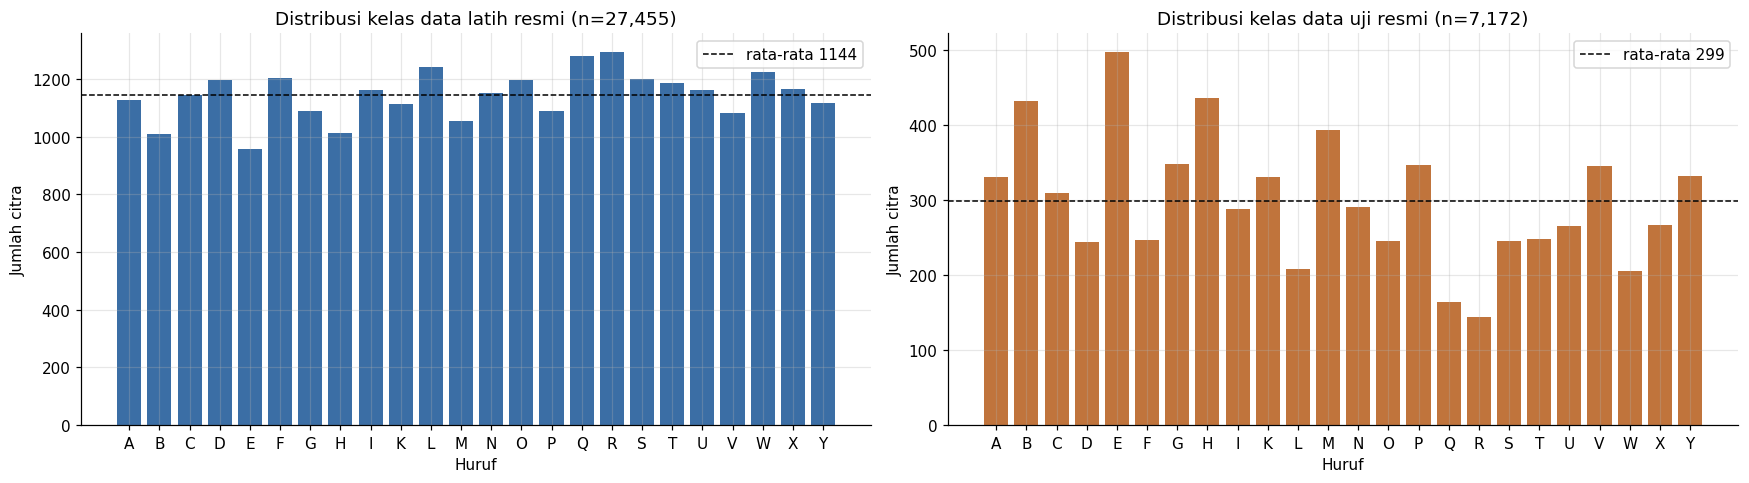

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].bar(CLASS_NAMES, train_counts.values, color="#3b6ea5")
ax[0].axhline(train_counts.mean(), ls="--", c="k", lw=1, label=f"rata-rata {train_counts.mean():.0f}")
ax[0].set_title(f"Distribusi kelas data latih resmi (n={len(df_train):,})"); ax[0].legend()
ax[1].bar(CLASS_NAMES, test_counts.values, color="#c0743c")
ax[1].axhline(test_counts.mean(), ls="--", c="k", lw=1, label=f"rata-rata {test_counts.mean():.0f}")
ax[1].set_title(f"Distribusi kelas data uji resmi (n={len(df_test):,})"); ax[1].legend()
for a in ax: a.set_xlabel("Huruf"); a.set_ylabel("Jumlah citra")
plt.tight_layout(); savefig("fig_distribusi_kelas"); plt.show()

[gambar tersimpan] outputs/figures/fig_contoh_per_kelas.png


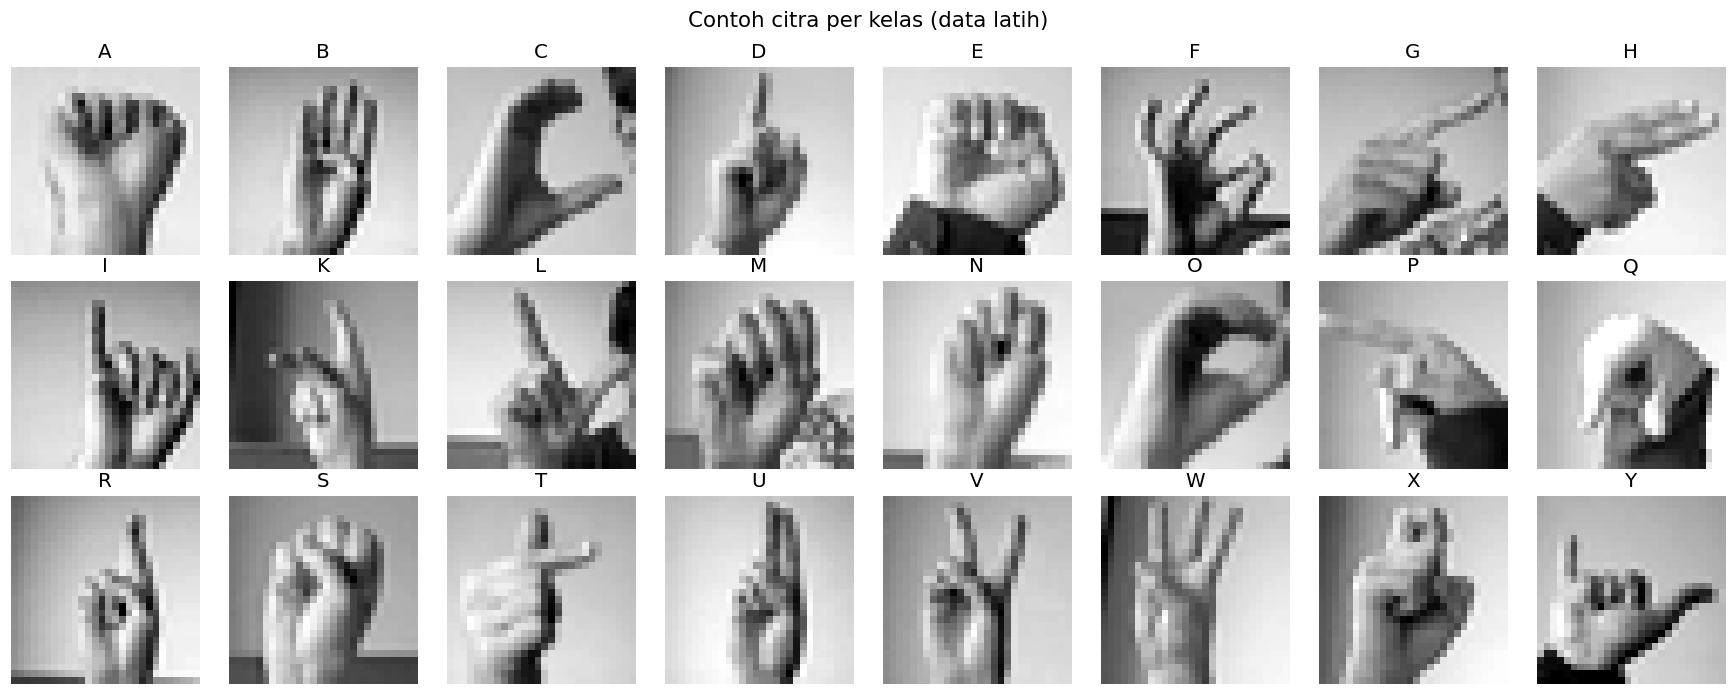

[gambar tersimpan] outputs/figures/fig_rata2_per_kelas.png


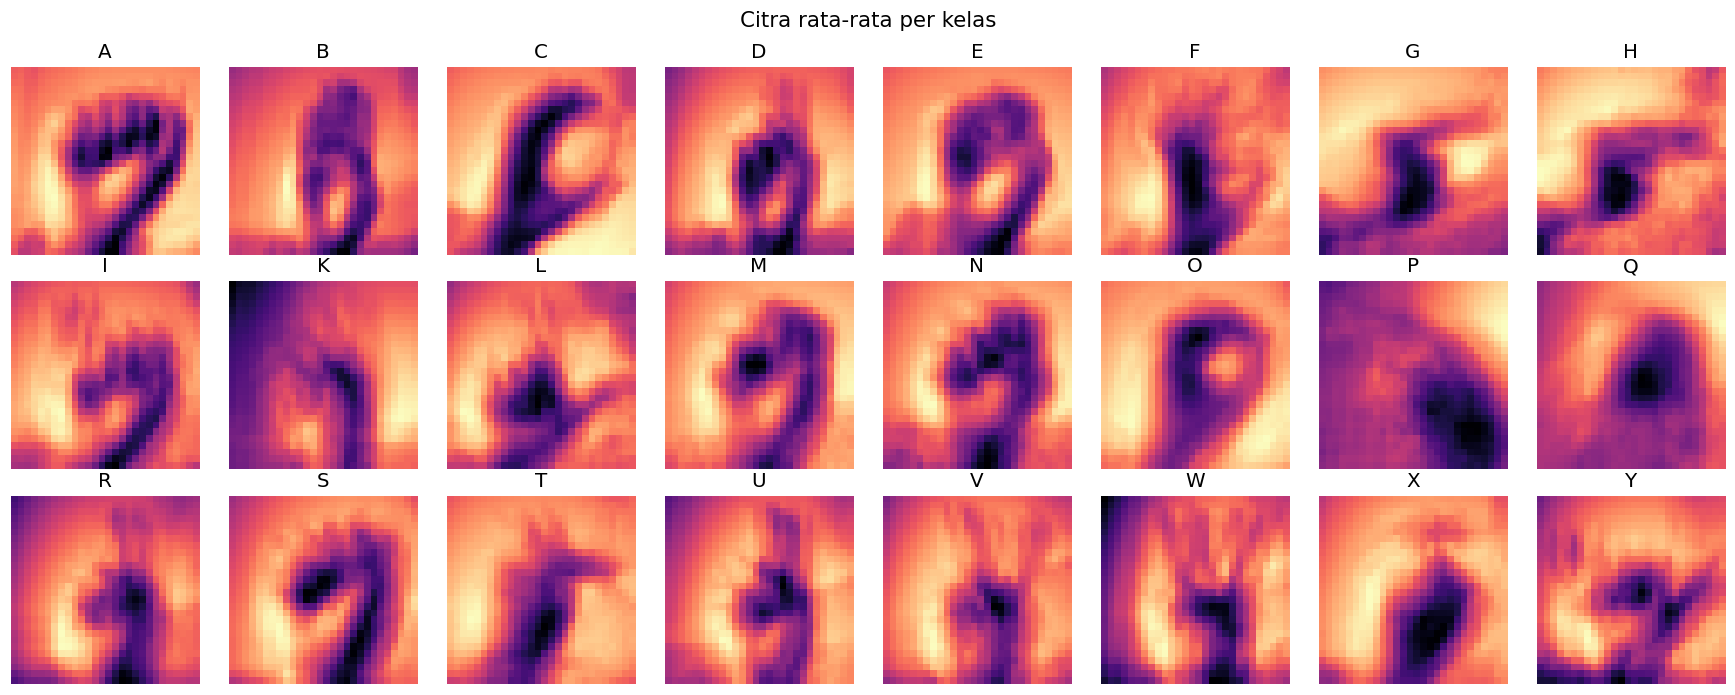

In [28]:
X_all_raw = df_train[pix_cols].values.astype(np.uint8).reshape(-1, 28, 28)
y_all_raw = df_train["label"].map(LABEL_MAP).values
X_te_raw  = df_test[pix_cols].values.astype(np.uint8).reshape(-1, 28, 28)

# Contoh satu citra per kelas
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_all_raw == i)[0][0]
    ax.imshow(X_all_raw[idx], cmap="gray"); ax.set_title(CLASS_NAMES[i], fontsize=13); ax.axis("off")
plt.suptitle("Contoh citra per kelas (data latih)", fontsize=14); plt.tight_layout()
savefig("fig_contoh_per_kelas"); plt.show()

# Citra rata-rata per kelas: memperlihatkan pola bentuk tangan yang khas tiap huruf
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_all_raw[y_all_raw == i].mean(0), cmap="magma"); ax.set_title(CLASS_NAMES[i], fontsize=13); ax.axis("off")
plt.suptitle("Citra rata-rata per kelas", fontsize=14); plt.tight_layout()
savefig("fig_rata2_per_kelas"); plt.show()

[gambar tersimpan] outputs/figures/fig_histogram_intensitas.png


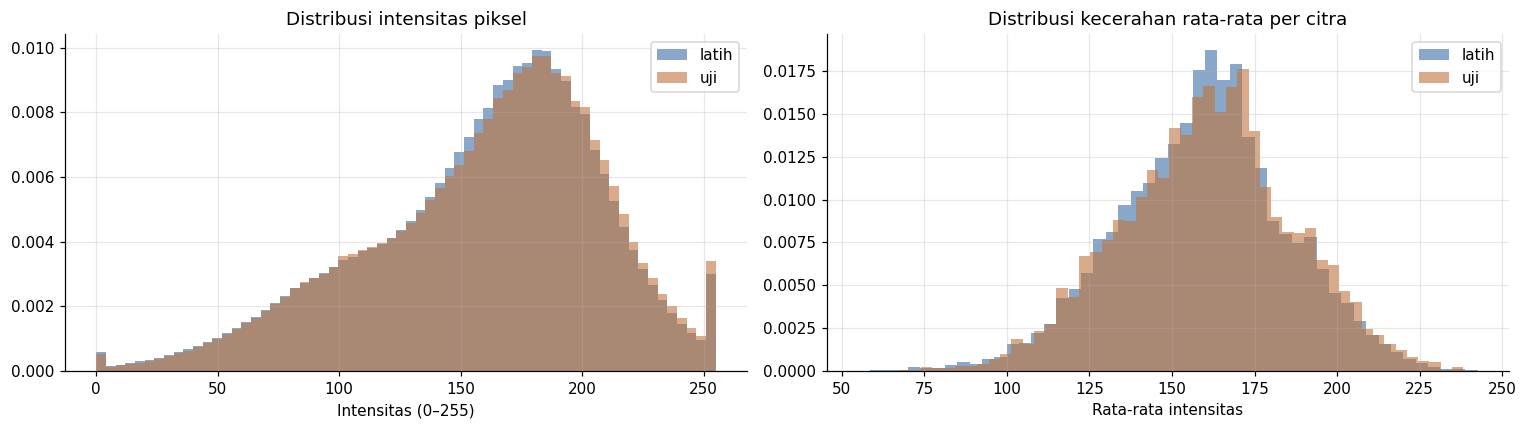

Mean±std piksel latih: 159.29 ± 48.77
Mean±std piksel uji  : 160.57 ± 49.04


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(X_all_raw.ravel(), bins=64, alpha=0.6, density=True, label="latih", color="#3b6ea5")
ax[0].hist(X_te_raw.ravel(),  bins=64, alpha=0.6, density=True, label="uji",   color="#c0743c")
ax[0].set_title("Distribusi intensitas piksel"); ax[0].set_xlabel("Intensitas (0–255)"); ax[0].legend()
mean_tr, mean_te = X_all_raw.reshape(len(X_all_raw), -1).mean(1), X_te_raw.reshape(len(X_te_raw), -1).mean(1)
ax[1].hist(mean_tr, bins=50, alpha=0.6, density=True, label="latih", color="#3b6ea5")
ax[1].hist(mean_te, bins=50, alpha=0.6, density=True, label="uji",   color="#c0743c")
ax[1].set_title("Distribusi kecerahan rata-rata per citra"); ax[1].set_xlabel("Rata-rata intensitas"); ax[1].legend()
plt.tight_layout(); savefig("fig_histogram_intensitas"); plt.show()

R["data"].update({
    "pixel_mean_train": float(X_all_raw.mean()), "pixel_std_train": float(X_all_raw.std()),
    "pixel_mean_test":  float(X_te_raw.mean()),  "pixel_std_test":  float(X_te_raw.std()),
})
print(f"Mean±std piksel latih: {X_all_raw.mean():.2f} ± {X_all_raw.std():.2f}")
print(f"Mean±std piksel uji  : {X_te_raw.mean():.2f} ± {X_te_raw.std():.2f}")

[gambar tersimpan] outputs/figures/fig_korelasi_piksel.png


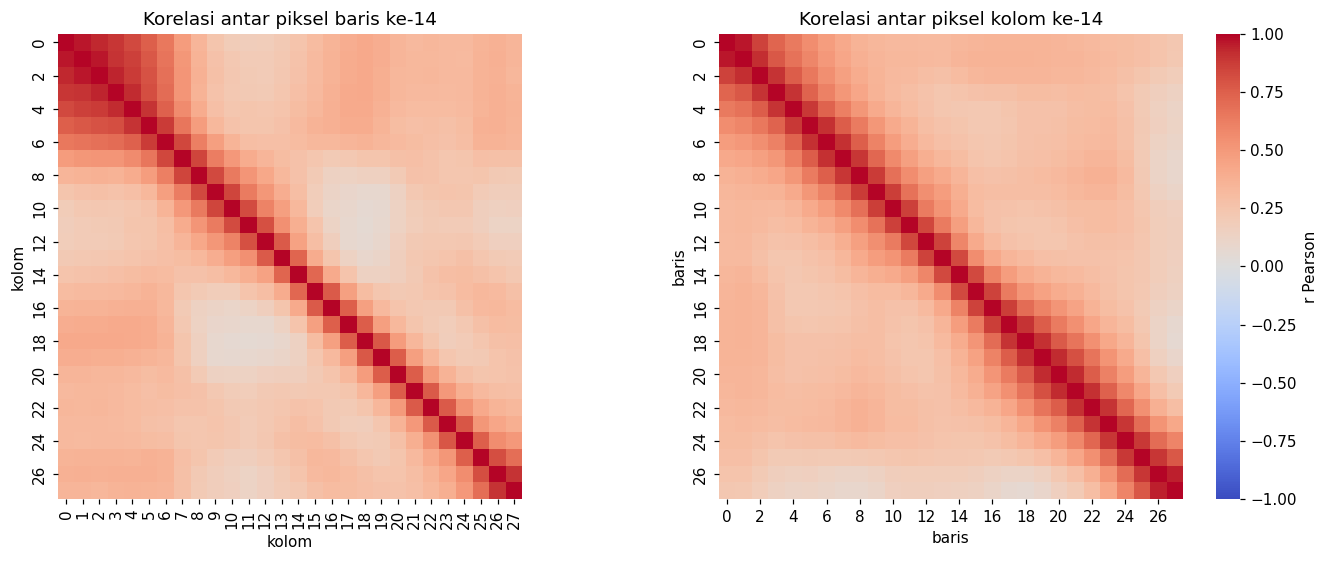

Rata-rata korelasi piksel bertetangga: 0.857 | piksel berjarak 10: 0.246


In [30]:
# Korelasi antarfitur (piksel). Untuk data citra, fitur = intensitas piksel.
# Ditampilkan korelasi Pearson antar 28 piksel pada baris tengah (baris ke-14) dan antar 28 piksel pada kolom tengah.
flat_tr = X_all_raw.reshape(len(X_all_raw), -1).astype("float32")
idx_row = [14 * 28 + c for c in range(28)]
idx_col = [r * 28 + 14 for r in range(28)]
corr_row = np.corrcoef(flat_tr[:, idx_row], rowvar=False)
corr_col = np.corrcoef(flat_tr[:, idx_col], rowvar=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
sns.heatmap(corr_row, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0], square=True, cbar=False)
ax[0].set_title("Korelasi antar piksel baris ke-14"); ax[0].set_xlabel("kolom"); ax[0].set_ylabel("kolom")
sns.heatmap(corr_col, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1], square=True, cbar_kws={"label": "r Pearson"})
ax[1].set_title("Korelasi antar piksel kolom ke-14"); ax[1].set_xlabel("baris"); ax[1].set_ylabel("baris")
for a_ in ax: a_.grid(False)
plt.tight_layout(); savefig("fig_korelasi_piksel"); plt.show()
tetangga = float(np.mean([corr_row[i, i + 1] for i in range(27)] + [corr_col[i, i + 1] for i in range(27)]))
jauh = float(np.mean([corr_row[i, i + 10] for i in range(18)] + [corr_col[i, i + 10] for i in range(18)]))
R["data"].update({"corr_tetangga": tetangga, "corr_jarak10": jauh})
print(f"Rata-rata korelasi piksel bertetangga: {tetangga:.3f} | piksel berjarak 10: {jauh:.3f}")

## 3. Praproses dan Pembagian Data
1. **Pembersihan**: tidak ada *missing value* atau nilai di luar [0, 255]. Hasil cek duplikat dicatat sebagai temuan dan tidak dihapus, karena data latih Kaggle memang berasal dari augmentasi beberapa citra asli.
2. **Re-indeks label**: label asli 0–24 (tanpa 9) dipetakan ke 0–23 agar sesuai dengan 24 neuron *softmax*.
3. **Normalisasi**: piksel dibagi 255 → rentang [0, 1] (`float32`).
4. **Reshape**: 784 → tensor `(28, 28, 1)` (tinggi, lebar, kanal).
5. **Pembagian data**: data latih resmi dibagi secara *stratified* menjadi **latih (90%)** dan **validasi (10%)**. **Data uji resmi (7.172 citra)** tidak disentuh sampai evaluasi akhir.

> Catatan: proyek lama memakai data uji sekaligus sebagai data validasi untuk *early stopping*. Itu adalah *data leakage*, sehingga di versi ini keduanya dipisah.

In [31]:
X_full = (X_all_raw.astype("float32") / 255.0)[..., np.newaxis]     # (27455, 28, 28, 1)
y_full = y_all_raw.astype("int32")
X_test = (X_te_raw.astype("float32") / 255.0)[..., np.newaxis]      # (7172, 28, 28, 1)
y_test = df_test["label"].map(LABEL_MAP).values.astype("int32")

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=VAL_SIZE, stratify=y_full, random_state=SEED)

INPUT_SHAPE = X_train.shape[1:]
print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}    y_val  : {y_val.shape}")
print(f"X_test : {X_test.shape}   y_test : {y_test.shape}")
print(f"Rentang setelah normalisasi: [{X_train.min():.1f}, {X_train.max():.1f}], dtype={X_train.dtype}")
R["data"].update({"n_train": len(X_train), "n_val": len(X_val), "n_test": len(X_test),
                  "input_shape": list(INPUT_SHAPE)})

X_train: (24709, 28, 28, 1)  y_train: (24709,)
X_val  : (2746, 28, 28, 1)    y_val  : (2746,)
X_test : (7172, 28, 28, 1)   y_test : (7172,)
Rentang setelah normalisasi: [0.0, 1.0], dtype=float32


## 4. Representasi Data sebagai Tensor dengan TensorFlow (CPMK 1)
Sebuah citra adalah tensor rank-3 `(28, 28, 1)`, sedangkan satu *batch* adalah tensor rank-4 `(B, 28, 28, 1)`. Sel berikut mendemonstrasikan operasi tensor dasar: konversi, *indexing/slicing*, *broadcasting*, reduksi, *reshape*, perkalian matriks (operasi inti lapisan *Dense*), *softmax*, *one-hot*, dan diferensiasi otomatis dengan `tf.GradientTape`.

1) Konversi       : rank 4 | shape (32, 28, 28, 1) | dtype <dtype: 'float32'>
2) Slicing        : (20, 20, 1)
3) Broadcasting   : z-score -> mean -0.000, std 1.000
4) Reduksi        : citra rata-rata (28, 28, 1)
5) Reshape        : (32, 28, 28, 1) -> (32, 784)
6) MatMul+Softmax : (32, 24) | jumlah prob baris-0 = 1.0
7) One-hot        : (32, 24) | contoh label 0 -> 0
8) GradientTape   : L=9.0, dL/dw=-18.0 (analitik: -18.0)
[gambar tersimpan] outputs/figures/fig_tensor.png


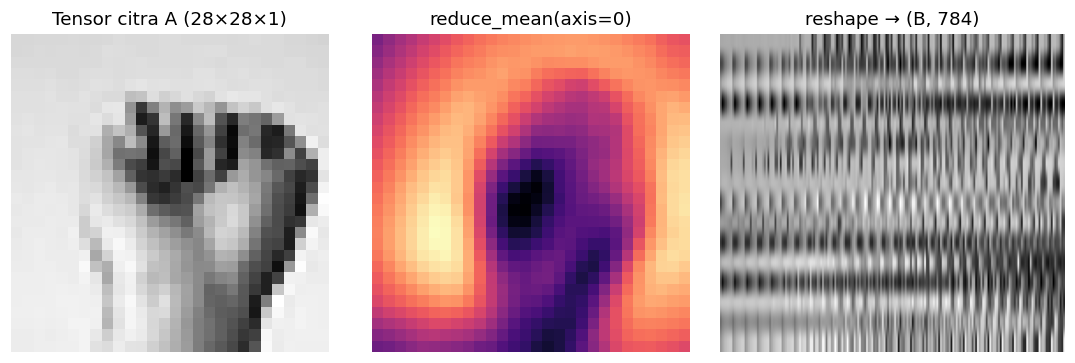

In [32]:
batch = tf.convert_to_tensor(X_train[:32])                       # tensor rank-4
print("1) Konversi       :", "rank", batch.ndim, "| shape", batch.shape, "| dtype", batch.dtype)

crop = batch[0, 4:24, 4:24, :]                                   # slicing satu citra
print("2) Slicing        :", crop.shape)

mu, sigma = tf.reduce_mean(batch), tf.math.reduce_std(batch)
z = (batch - mu) / sigma                                         # broadcasting skalar ke rank-4
print(f"3) Broadcasting   : z-score -> mean {float(tf.reduce_mean(z)):.3f}, std {float(tf.math.reduce_std(z)):.3f}")

mean_img = tf.reduce_mean(tf.convert_to_tensor(X_train), axis=0) # reduksi sepanjang sumbu batch
print("4) Reduksi        : citra rata-rata", mean_img.shape)

flat = tf.reshape(batch, (-1, 28 * 28))                          # (32, 784)
print("5) Reshape        :", batch.shape, "->", flat.shape)

W = tf.random.normal((784, N_CLASSES), stddev=0.01, seed=SEED); b = tf.zeros((N_CLASSES,))
logits = tf.matmul(flat, W) + b                                  # y = xW + b
probs = tf.nn.softmax(logits)
print("6) MatMul+Softmax :", logits.shape, "| jumlah prob baris-0 =", float(tf.reduce_sum(probs[0])))

onehot = tf.one_hot(y_train[:32], depth=N_CLASSES)
print("7) One-hot        :", onehot.shape, "| contoh label", int(y_train[0]), "->", int(tf.argmax(onehot[0])))

w = tf.Variable(2.0)
with tf.GradientTape() as tape:
    loss = (3.0 * w - 9.0) ** 2                                  # L(w) = (3w-9)^2
grad = tape.gradient(loss, w)                                    # dL/dw = 6(3w-9) = -18 di w=2
print(f"8) GradientTape   : L={float(loss):.1f}, dL/dw={float(grad):.1f} (analitik: -18.0)")

R["tensor"] = {"batch_shape": list(batch.shape), "flat_shape": list(flat.shape), "logits_shape": list(logits.shape),
               "grad_demo": float(grad), "mean_img_shape": list(mean_img.shape)}

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(batch[0, ..., 0], cmap="gray"); ax[0].set_title(f"Tensor citra {CLASS_NAMES[y_train[0]]} (28×28×1)")
ax[1].imshow(mean_img[..., 0], cmap="magma"); ax[1].set_title("reduce_mean(axis=0)")
ax[2].imshow(tf.reshape(flat[:16], (16, 784))[:, ::4], aspect="auto", cmap="gray"); ax[2].set_title("reshape → (B, 784)")
for a in ax: a.axis("off")
plt.tight_layout(); savefig("fig_tensor"); plt.show()

## 5. *Input Pipeline* dengan `tf.data`
Alur pipeline: `from_tensor_slices → cache → shuffle → map(augmentasi fotometrik) → batch → map(augmentasi geometrik) → prefetch(AUTOTUNE)`.

* **cache**: data disimpan di memori setelah epoch pertama.
* **shuffle**: urutan diacak ulang setiap epoch (buffer = ukuran data).
* **augmentasi** (khusus data latih model akhir E5): rotasi ±10°, *zoom* ±10%, translasi ±10%, serta kecerahan dan kontras acak. **Tidak ada *flip* horizontal**, karena membalik citra mengubah tangan kanan menjadi tangan kiri.
* **prefetch**: CPU menyiapkan *batch* berikutnya selagi GPU melatih *batch* saat ini.

In [33]:
AUTOTUNE = tf.data.AUTOTUNE

geo_augment = keras.Sequential([
    layers.RandomRotation(0.03, fill_mode="nearest", seed=SEED),          # 0.03 × 360° ≈ ±10.8°
    layers.RandomZoom(0.10, fill_mode="nearest", seed=SEED),
    layers.RandomTranslation(0.10, 0.10, fill_mode="nearest", seed=SEED),
], name="augmentasi_geometrik")

def photometric_augment(x, y):
    x = tf.image.random_brightness(x, max_delta=0.10)
    x = tf.image.random_contrast(x, lower=0.8, upper=1.2)
    return tf.clip_by_value(x, 0.0, 1.0), y

def make_dataset(X, y, training=False, augment=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).cache()
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(photometric_augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    if augment:
        ds = ds.map(lambda x, y: (geo_augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds     = make_dataset(X_train, y_train, training=True)
train_ds_aug = make_dataset(X_train, y_train, training=True, augment=True)
val_ds       = make_dataset(X_val, y_val)
test_ds      = make_dataset(X_test, y_test)

print("Element spec:", train_ds.element_spec)
print("Jumlah batch/epoch (latih):", int(train_ds.cardinality()))

Element spec: (TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Jumlah batch/epoch (latih): 194


[gambar tersimpan] outputs/figures/fig_augmentasi.png


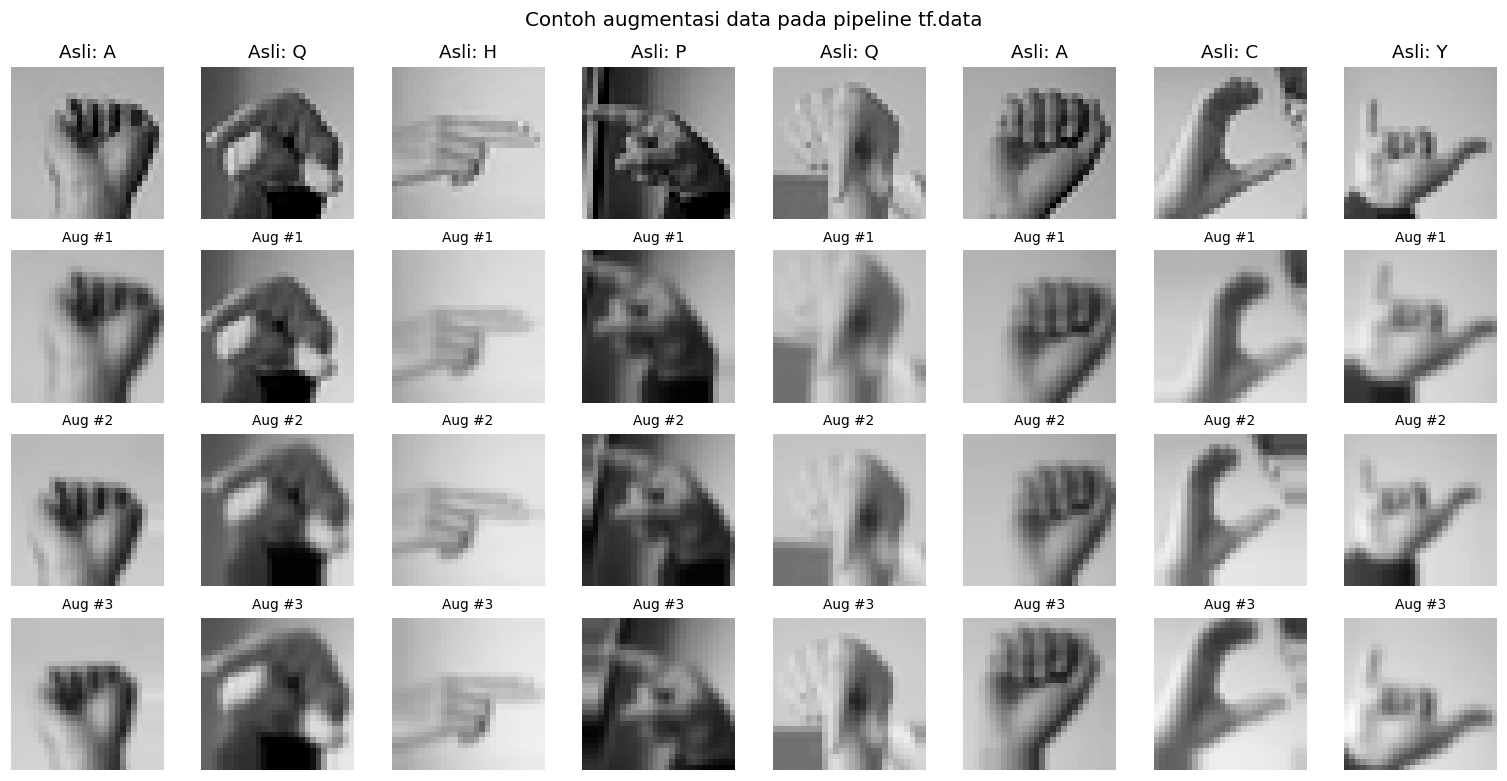

Throughput tanpa cache/prefetch : 422,903 citra/detik
Throughput cache+shuffle+prefetch: 309,063 citra/detik
Throughput dengan augmentasi     : 9,455 citra/detik


In [34]:
# Visualisasi augmentasi: baris pertama citra asli, baris berikutnya hasil augmentasi acak
sample_x, sample_y = X_train[:8], y_train[:8]
fig, axes = plt.subplots(4, 8, figsize=(14, 7.2))
for j in range(8):
    axes[0, j].imshow(sample_x[j, ..., 0], cmap="gray", vmin=0, vmax=1); axes[0, j].set_title(f"Asli: {CLASS_NAMES[sample_y[j]]}")
for r in range(1, 4):
    aug, _ = photometric_augment(tf.convert_to_tensor(sample_x), None)
    aug = geo_augment(aug, training=True).numpy()
    for j in range(8):
        axes[r, j].imshow(aug[j, ..., 0], cmap="gray", vmin=0, vmax=1); axes[r, j].set_title(f"Aug #{r}", fontsize=9)
for a in axes.flat: a.axis("off")
plt.suptitle("Contoh augmentasi data pada pipeline tf.data", fontsize=13); plt.tight_layout()
savefig("fig_augmentasi"); plt.show()

# Throughput pipeline (citra/detik). Epoch pertama mengisi cache, jadi diukur pada pass kedua.
def throughput(ds, n_items):
    for _ in ds: pass
    t0 = time.time()
    for _ in ds: pass
    return n_items / (time.time() - t0)

naive_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(BATCH_SIZE)
tp_naive = throughput(naive_ds, len(X_train))
tp_plain = throughput(train_ds, len(X_train))
tp_aug   = throughput(train_ds_aug, len(X_train))
R["pipeline"] = {"batch_size": BATCH_SIZE, "shuffle_buffer": len(X_train), "steps_per_epoch": int(train_ds.cardinality()),
                 "throughput_naive": tp_naive, "throughput_plain": tp_plain, "throughput_aug": tp_aug}
print(f"Throughput tanpa cache/prefetch : {tp_naive:,.0f} citra/detik")
print(f"Throughput cache+shuffle+prefetch: {tp_plain:,.0f} citra/detik")
print(f"Throughput dengan augmentasi     : {tp_aug:,.0f} citra/detik")

## 6. Perceptron, Neuron Sigmoid, dan MLP dengan *Backpropagation* Manual (CPMK 2)
Bagian ini memperlihatkan konsep dasar sebelum memakai `model.fit()`:

* **6.1 Perceptron Rosenblatt**: klasifikasi biner huruf **A vs B** dengan fungsi tangga dan aturan pembaruan $w \leftarrow w + \eta\,(y-\hat y)\,x$.
* **6.2 Neuron sigmoid + *gradient descent***: tugas yang sama, tetapi dengan *binary cross-entropy* dan gradien dari `tf.GradientTape`.
* **6.3 MLP 784–128–24 dengan *custom training loop***: bobot berupa `tf.Variable`, *forward pass* manual, *backpropagation* otomatis, dan pembaruan *mini-batch* SGD.

In [35]:
# ---------- 6.1 Perceptron Rosenblatt (A vs B) ----------
cA, cB = CLASS_NAMES.index("A"), CLASS_NAMES.index("B")
def biner(X, y):
    m = np.isin(y, [cA, cB])
    return X[m].reshape(m.sum(), -1).astype("float32"), (y[m] == cB).astype("float32")
Xp_tr, yp_tr = biner(X_train, y_train)
Xp_te, yp_te = biner(X_test, y_test)

w_p = tf.Variable(tf.zeros(784)); b_p = tf.Variable(0.0); ETA = 0.1

@tf.function
def perceptron_epoch(X, y):
    errors = tf.constant(0.0)
    for i in tf.range(tf.shape(X)[0]):
        y_hat = tf.cast(tf.tensordot(w_p, X[i], 1) + b_p >= 0.0, tf.float32)   # fungsi tangga
        delta = ETA * (y[i] - y_hat)
        w_p.assign_add(delta * X[i]); b_p.assign_add(delta)
        errors += tf.abs(y[i] - y_hat)
    return errors

perc_errors = []
P_EPOCHS = 3 if QUICK_MODE else 15
for ep in range(P_EPOCHS):
    perm = np.random.permutation(len(Xp_tr))
    perc_errors.append(int(perceptron_epoch(tf.constant(Xp_tr[perm]), tf.constant(yp_tr[perm]))))
pred_p = lambda X: (X @ w_p.numpy() + b_p.numpy() >= 0).astype("float32")
perc_tr_acc, perc_te_acc = (pred_p(Xp_tr) == yp_tr).mean(), (pred_p(Xp_te) == yp_te).mean()
print(f"Data biner A vs B: latih {len(Xp_tr)}, uji {len(Xp_te)}")
print("Kesalahan per epoch:", perc_errors)
print(f"Perceptron -> akurasi latih {perc_tr_acc:.4f} | akurasi uji {perc_te_acc:.4f}")

Data biner A vs B: latih 1922, uji 763
Kesalahan per epoch: [45, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Perceptron -> akurasi latih 1.0000 | akurasi uji 1.0000


In [36]:
# ---------- 6.2 Neuron sigmoid + gradient descent (BCE) ----------
w_s = tf.Variable(tf.random.normal((784, 1), stddev=0.01, seed=SEED)); b_s = tf.Variable(tf.zeros((1,)))
Xs_tr, ys_tr = tf.constant(Xp_tr), tf.constant(yp_tr[:, None])
LR_S, STEPS = 0.5, (20 if QUICK_MODE else 300)
sig_loss = []
for step in range(STEPS):
    with tf.GradientTape() as tape:
        p = tf.sigmoid(Xs_tr @ w_s + b_s)
        loss = tf.reduce_mean(keras.losses.binary_crossentropy(ys_tr, p))
    gw, gb = tape.gradient(loss, [w_s, b_s])          # backpropagation
    w_s.assign_sub(LR_S * gw); b_s.assign_sub(LR_S * gb) # gradient descent
    sig_loss.append(float(loss))
pred_s = lambda X: (tf.sigmoid(X @ w_s + b_s).numpy().ravel() >= 0.5).astype("float32")
sig_tr_acc, sig_te_acc = (pred_s(Xp_tr) == yp_tr).mean(), (pred_s(Xp_te) == yp_te).mean()
print(f"Loss awal {sig_loss[0]:.4f} -> akhir {sig_loss[-1]:.4f}")
print(f"Neuron sigmoid -> akurasi latih {sig_tr_acc:.4f} | akurasi uji {sig_te_acc:.4f}")

Loss awal 0.6897 -> akhir 8.4025
Neuron sigmoid -> akurasi latih 0.4729 | akurasi uji 0.5662


Epoch 1: loss=2.6981  val_acc=0.0940
Epoch 2: loss=2.1363  val_acc=0.1580
Epoch 3: loss=1.7205  val_acc=0.3063
Epoch 4: loss=1.4751  val_acc=0.3521
Epoch 5: loss=1.2918  val_acc=0.0459
Epoch 6: loss=1.4679  val_acc=0.1854
Epoch 7: loss=1.5189  val_acc=0.2302
Epoch 8: loss=1.3032  val_acc=0.3358
MLP manual -> akurasi uji 0.3006
[gambar tersimpan] outputs/figures/fig_perceptron_mlp_manual.png


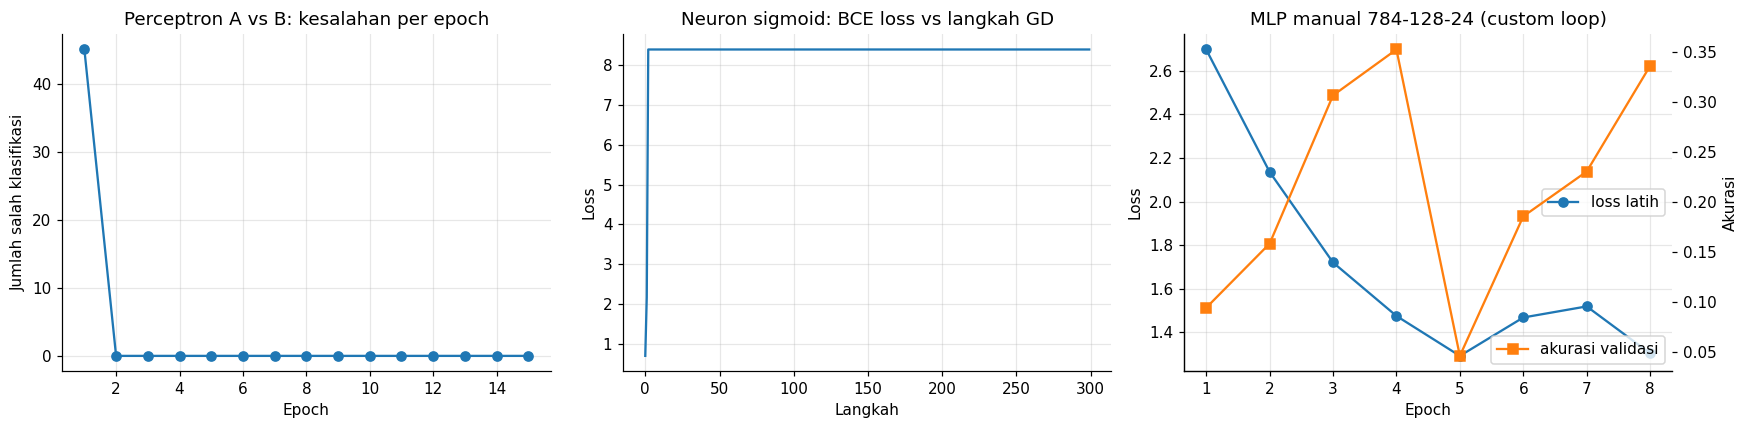

In [37]:
# ---------- 6.3 MLP manual 784-128-24 dengan custom training loop ----------
he = keras.initializers.HeNormal(seed=SEED)
W1 = tf.Variable(he((784, 128)));       b1 = tf.Variable(tf.zeros(128))
W2 = tf.Variable(he((128, N_CLASSES))); b2 = tf.Variable(tf.zeros(N_CLASSES))
params = [W1, b1, W2, b2]
LR_M = 0.1
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def forward(x):
    h = tf.nn.relu(tf.reshape(x, (-1, 784)) @ W1 + b1)    # lapisan tersembunyi (ReLU)
    return h @ W2 + b2                                    # logits

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        loss = loss_fn(y, forward(x))
    grads = tape.gradient(loss, params)                    # backpropagation (chain rule)
    for p_, g_ in zip(params, grads):
        p_.assign_sub(LR_M * g_)                           # mini-batch SGD
    return loss

def acc_manual(ds):
    benar = total = 0
    for x, y in ds:
        benar += int(tf.reduce_sum(tf.cast(tf.argmax(forward(x), 1, output_type=tf.int32) == y, tf.int32)))
        total += int(tf.shape(y)[0])
    return benar / total

mlp_manual = {"epoch": [], "loss": [], "val_acc": []}
for ep in range(2 if QUICK_MODE else 8):
    losses = [float(train_step(x, y)) for x, y in train_ds]
    mlp_manual["epoch"].append(ep + 1); mlp_manual["loss"].append(float(np.mean(losses)))
    mlp_manual["val_acc"].append(acc_manual(val_ds))
    print(f"Epoch {ep+1}: loss={mlp_manual['loss'][-1]:.4f}  val_acc={mlp_manual['val_acc'][-1]:.4f}")
mlp_manual["test_acc"] = acc_manual(test_ds)
print(f"MLP manual -> akurasi uji {mlp_manual['test_acc']:.4f}")

R["perceptron"] = {"classes": ["A", "B"], "n_train": len(Xp_tr), "n_test": len(Xp_te), "eta": ETA,
                   "epochs": P_EPOCHS, "errors": perc_errors, "train_acc": float(perc_tr_acc), "test_acc": float(perc_te_acc),
                   "sigmoid": {"lr": LR_S, "steps": STEPS, "loss_start": sig_loss[0], "loss_end": sig_loss[-1],
                               "train_acc": float(sig_tr_acc), "test_acc": float(sig_te_acc)},
                   "mlp_manual": {**mlp_manual, "lr": LR_M, "arsitektur": "784-128(ReLU)-24"}}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(range(1, len(perc_errors) + 1), perc_errors, "o-"); ax[0].set_title("Perceptron A vs B: kesalahan per epoch")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Jumlah salah klasifikasi")
ax[1].plot(sig_loss); ax[1].set_title("Neuron sigmoid: BCE loss vs langkah GD"); ax[1].set_xlabel("Langkah"); ax[1].set_ylabel("Loss")
ax[2].plot(mlp_manual["epoch"], mlp_manual["loss"], "o-", label="loss latih")
ax2 = ax[2].twinx(); ax2.plot(mlp_manual["epoch"], mlp_manual["val_acc"], "s-", c="C1", label="akurasi validasi")
ax[2].set_title("MLP manual 784-128-24 (custom loop)"); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("Loss"); ax2.set_ylabel("Akurasi")
ax[2].legend(loc="center right"); ax2.legend(loc="lower right"); ax2.grid(False)
plt.tight_layout(); savefig("fig_perceptron_mlp_manual"); plt.show()

## 7. Utilitas Training: *Callback*, *Monitoring*, dan *Learning Rate Scheduling*
* **EarlyStopping** (`monitor='val_loss'`, `restore_best_weights=True`) menghentikan training saat validasi tidak membaik.
* **ModelCheckpoint** menyimpan bobot terbaik (berdasarkan `val_loss`).
* **ReduceLROnPlateau** mengalikan *learning rate* dengan 0,5 jika `val_loss` tidak turun selama 3 epoch.
* **CSVLogger** dan **TensorBoard** mencatat seluruh metrik per epoch untuk *model monitoring*.
* **LRLogger** (*callback* kustom) mencatat *learning rate* setiap epoch.

Fungsi `run_experiment()` menjalankan satu eksperimen secara lengkap: *compile*, *fit*, memuat ulang bobot terbaik, lalu evaluasi pada data validasi dan uji. Semua hasilnya dicatat di `R['experiments']`.

In [38]:
class LRLogger(keras.callbacks.Callback):
    # Mencatat learning rate yang dipakai pada setiap epoch ke dalam logs['lr'].
    def on_epoch_end(self, epoch, logs=None):
        lr = self.model.optimizer.learning_rate
        try:
            lr = float(keras.ops.convert_to_numpy(lr))
        except Exception:
            lr = float(np.array(lr))
        if logs is not None:
            logs["lr"] = lr

def make_callbacks(exp_id, patience=8, reduce_lr=True, monitor_extra=True):
    cbs = [LRLogger(),
           keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
           keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, f"{exp_id}_best.weights.h5"),
                                           monitor="val_loss", save_best_only=True, save_weights_only=True)]
    if monitor_extra:
        cbs += [keras.callbacks.CSVLogger(os.path.join(LOG_DIR, f"{exp_id}_log.csv")),
                keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, "tensorboard", exp_id))]
    if reduce_lr:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1))
    return cbs

def predict_labels(model, ds):
    prob = model.predict(ds, verbose=0)
    return prob, prob.argmax(1)

def metrik(y_true, y_pred):
    return {"acc": float(accuracy_score(y_true, y_pred)),
            "macro_p": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_r": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0))}

def arsitektur(model):
    rows = []
    for l in model.layers:
        try:
            shp = str(tuple(l.output.shape))
        except Exception:
            shp = "-"
        rows.append([l.name, l.__class__.__name__, shp, int(l.count_params())])
    return rows

HIST, MODELS, PROBS = {}, {}, {}

def run_experiment(exp_id, nama, deskripsi, model, optimizer, train_data, epochs, patience=8,
                   reduce_lr=True, augment=False, opt_name=""):
    keras.utils.set_random_seed(SEED)
    if QUICK_MODE:
        epochs = 2
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    print(f"\n{'='*70}\n{exp_id}: {nama}\n{deskripsi}\nParameter: {model.count_params():,}\n{'='*70}")
    t0 = time.time()
    h = model.fit(train_data, validation_data=val_ds, epochs=epochs,
                  callbacks=make_callbacks(exp_id, patience, reduce_lr), verbose=2)
    t_train = time.time() - t0
    model.load_weights(os.path.join(MODEL_DIR, f"{exp_id}_best.weights.h5"))   # pastikan bobot terbaik
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmin(hist["val_loss"]))
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    prob, y_pred = predict_labels(model, test_ds)
    m = metrik(y_test, y_pred)
    rec = {"id": exp_id, "nama": nama, "deskripsi": deskripsi, "optimizer": opt_name,
           "augmentasi": augment, "params": int(model.count_params()), "epochs_max": epochs,
           "epochs_run": len(hist["loss"]), "best_epoch": best + 1, "train_time_s": t_train,
           "train_acc": hist["accuracy"][best], "train_loss": hist["loss"][best],
           "val_acc": float(val_acc), "val_loss": float(val_loss),
           "test_acc": float(test_acc), "test_loss": float(test_loss),
           "macro_p": m["macro_p"], "macro_r": m["macro_r"], "macro_f1": m["macro_f1"],
           "weighted_f1": m["weighted_f1"], "lr_akhir": hist.get("lr", [None])[-1],
           "arsitektur": arsitektur(model), "history": hist}
    R["experiments"] = [e for e in R["experiments"] if e["id"] != exp_id] + [rec]
    HIST[exp_id], MODELS[exp_id], PROBS[exp_id] = hist, model, prob
    print(f"\n>> {exp_id} selesai dalam {t_train:.1f} s | epoch terbaik {best+1}/{len(hist['loss'])}")
    print(f">> Val acc {val_acc:.4f} | TEST acc {test_acc:.4f} | Macro-F1 {m['macro_f1']:.4f} | Test loss {test_loss:.4f}")
    return model

def plot_history(exp_id, key):
    h = HIST[exp_id]
    fig, ax = plt.subplots(1, 3 if "lr" in h else 2, figsize=(16, 4))
    ep = range(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], label="latih"); ax[0].plot(ep, h["val_loss"], label="validasi"); ax[0].set_title(f"{exp_id}: Loss")
    ax[1].plot(ep, h["accuracy"], label="latih"); ax[1].plot(ep, h["val_accuracy"], label="validasi"); ax[1].set_title(f"{exp_id}: Akurasi")
    if "lr" in h:
        ax[2].plot(ep, h["lr"], "o-", c="C2"); ax[2].set_yscale("log"); ax[2].set_title(f"{exp_id}: Learning rate")
    for a in ax: a.set_xlabel("Epoch")
    ax[0].legend(); ax[1].legend(); plt.tight_layout(); savefig(key); plt.show()

[gambar tersimpan] outputs/figures/fig_lr_schedule.png


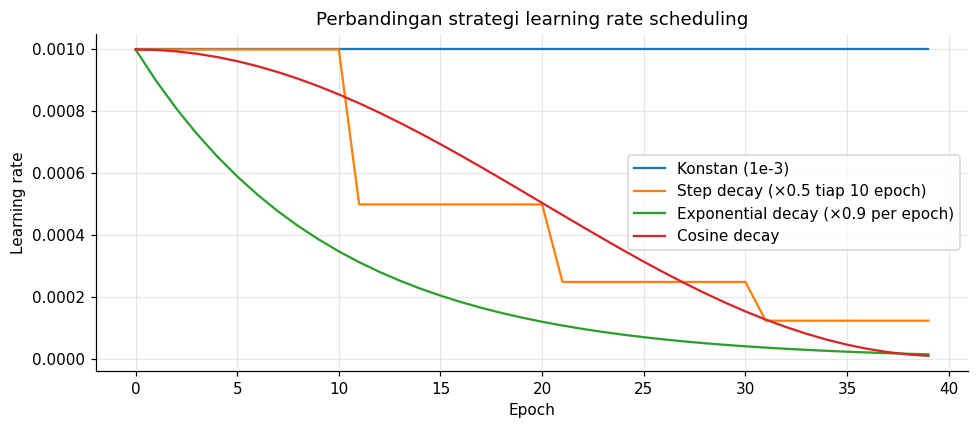

In [39]:
# Visualisasi beberapa strategi learning rate scheduling (konsep)
spe, N_EP = int(train_ds.cardinality()), 40           # steps per epoch, jumlah epoch ilustrasi
sched = {
    "Konstan (1e-3)": lambda step: 1e-3,
    "Step decay (×0.5 tiap 10 epoch)": keras.optimizers.schedules.PiecewiseConstantDecay(
        [10 * spe, 20 * spe, 30 * spe], [1e-3, 5e-4, 2.5e-4, 1.25e-4]),
    "Exponential decay (×0.9 per epoch)": keras.optimizers.schedules.ExponentialDecay(1e-3, decay_steps=spe, decay_rate=0.9),
    "Cosine decay": keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=N_EP * spe, alpha=0.01),
}
plt.figure(figsize=(9, 4))
for name, s in sched.items():
    plt.plot(range(N_EP), [float(s(e * spe)) for e in range(N_EP)], label=name)
plt.xlabel("Epoch"); plt.ylabel("Learning rate"); plt.title("Perbandingan strategi learning rate scheduling")
plt.legend(); plt.tight_layout(); savefig("fig_lr_schedule"); plt.show()

## 8. Definisi Arsitektur Model
| ID | Model | Ringkasan |
|---|---|---|
| E1 | MLP *baseline* | Flatten → Dense 256 → Dense 128 → Softmax 24, SGD η=0,01, tanpa regularisasi |
| E2 | MLP teregularisasi | Dense 512/256/128 + BatchNorm + Dropout 0,3, Adam, ReduceLROnPlateau |
| E3 | CNN *baseline* | Conv32 → Pool → Conv64 → Pool → Dense 128 → Softmax, Adam |
| E4 | CNN teregularisasi | 3 blok konvolusi (32-32 / 64-64 / 128) + BatchNorm + Dropout, Adam, ReduceLROnPlateau |
| E5 | **CNN teregularisasi + augmentasi (model akhir)** | Arsitektur E4 + augmentasi pada pipeline `tf.data` |

Seluruh lapisan ReLU menggunakan inisialisasi **He normal**. Lapisan output menggunakan **softmax** dengan *loss* **sparse categorical cross-entropy**.

In [40]:
def build_mlp_baseline():
    return keras.Sequential([
        keras.Input(INPUT_SHAPE), layers.Flatten(name="flatten"),
        layers.Dense(256, activation="relu", kernel_initializer="he_normal", name="dense_256"),
        layers.Dense(128, activation="relu", kernel_initializer="he_normal", name="dense_128"),
        layers.Dense(N_CLASSES, activation="softmax", name="output_softmax")], name="E1_MLP_Baseline")

def build_mlp_act(act):
    init = "he_normal" if act == "relu" else "glorot_uniform"
    return keras.Sequential([
        keras.Input(INPUT_SHAPE), layers.Flatten(),
        layers.Dense(256, activation=act, kernel_initializer=init),
        layers.Dense(128, activation=act, kernel_initializer=init),
        layers.Dense(N_CLASSES, activation="softmax")], name=f"MLP_{act}")

def dense_block(units, drop, name):
    return [layers.Dense(units, use_bias=False, kernel_initializer="he_normal", name=f"{name}_dense"),
            layers.BatchNormalization(name=f"{name}_bn"), layers.Activation("relu", name=f"{name}_relu"),
            layers.Dropout(drop, name=f"{name}_drop")]

def build_mlp_reg():
    return keras.Sequential([keras.Input(INPUT_SHAPE), layers.Flatten(name="flatten")]
                            + dense_block(512, 0.3, "fc1") + dense_block(256, 0.3, "fc2") + dense_block(128, 0.3, "fc3")
                            + [layers.Dense(N_CLASSES, activation="softmax", name="output_softmax")], name="E2_MLP_Reg")

def build_cnn_baseline():
    return keras.Sequential([
        keras.Input(INPUT_SHAPE),
        layers.Conv2D(32, 3, padding="same", activation="relu", kernel_initializer="he_normal", name="conv1"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", kernel_initializer="he_normal", name="conv2"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", kernel_initializer="he_normal", name="dense_128"),
        layers.Dense(N_CLASSES, activation="softmax", name="output_softmax")], name="E3_CNN_Baseline")

def conv_bn(filters, name):
    return [layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer="he_normal", name=f"{name}_conv"),
            layers.BatchNormalization(name=f"{name}_bn"), layers.Activation("relu", name=f"{name}_relu")]

def build_cnn_reg(name="E4_CNN_Reg"):
    return keras.Sequential(
        [keras.Input(INPUT_SHAPE)]
        + conv_bn(32, "b1c1") + conv_bn(32, "b1c2") + [layers.MaxPooling2D(2, name="b1_pool"), layers.Dropout(0.25, name="b1_drop")]
        + conv_bn(64, "b2c1") + conv_bn(64, "b2c2") + [layers.MaxPooling2D(2, name="b2_pool"), layers.Dropout(0.25, name="b2_drop")]
        + conv_bn(128, "b3c1") + [layers.MaxPooling2D(2, name="b3_pool"), layers.Dropout(0.30, name="b3_drop")]
        + [layers.Flatten(name="flatten")] + dense_block(256, 0.4, "fc")
        + [layers.Dense(N_CLASSES, activation="softmax", name="output_softmax")], name=name)

for fn in (build_mlp_baseline, build_mlp_reg, build_cnn_baseline, build_cnn_reg):
    m = fn(); print(f"{m.name:<20} parameter: {m.count_params():>9,}")
build_cnn_reg("E5_CNN_Reg_Aug").summary()

E1_MLP_Baseline      parameter:   236,952
E2_MLP_Reg           parameter:   571,928
E3_CNN_Baseline      parameter:   423,448
E4_CNN_Reg           parameter:   441,912


Model: "E5_CNN_Reg_Aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ b1c1_conv (Conv2D)              │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1c1_bn (BatchNormalization)    │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1c1_relu (Activation)          │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1c2_conv (Conv2D)              │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1c2_bn (BatchNormalization)    │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1c2_relu (Activation)          │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2c1_conv (Conv2D)              │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2c1_bn (BatchNormalization)    │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2c1_relu (Activation)          │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2c2_conv (Conv2D)              │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2c2_bn (BatchNormalization)    │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2c2_relu (Activation)          │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (Dropout)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3c1_conv (Conv2D)              │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3c1_bn (BatchNormalization)    │ (None, 7, 7, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3c1_relu (Activation)          │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_pool (MaxPooling2D)          │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_drop (Dropout)               │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_dense (Dense)                │ (None, 256)            │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_bn (BatchNormalization)      │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_relu (Activation)            │ (None, 256)            │             

 Total params: 441,912 (1.69 MB)

 Trainable params: 440,760 (1.68 MB)

 Non-trainable params: 1,152 (4.50 KB)

## 9. Studi Pendahuluan: Fungsi Aktivasi dan Optimizer
**9.1 Fungsi aktivasi**: MLP 784–256–128–24 dilatih dengan *sigmoid*, *tanh*, dan *ReLU* (Adam, 15 epoch) untuk melihat pengaruh aktivasi terhadap kecepatan konvergensi.

**9.2 Optimizer**: arsitektur CNN E4 dilatih 10 epoch dengan SGD, SGD+Momentum, RMSProp, dan Adam tanpa *scheduler* agar perbandingannya adil. Hasil studi ini menjadi dasar pemilihan ReLU dan Adam untuk E2–E5.

sigmoid  val_acc epoch-1 0.3871 | akhir 0.9246 | test 0.7217
tanh     val_acc epoch-1 0.4843 | akhir 1.0000 | test 0.7784
relu     val_acc epoch-1 0.4607 | akhir 0.9971 | test 0.7482
[gambar tersimpan] outputs/figures/fig_aktivasi.png


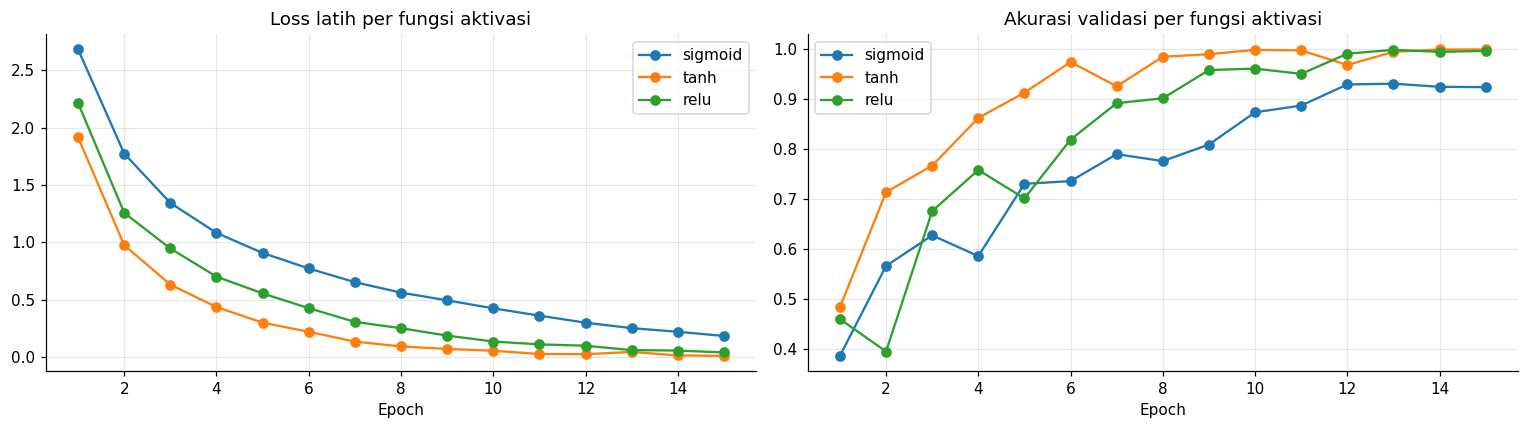

In [41]:
ACT_EPOCHS = 2 if QUICK_MODE else 15
for act in ["sigmoid", "tanh", "relu"]:
    keras.utils.set_random_seed(SEED)
    m = build_mlp_act(act)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(train_ds, validation_data=val_ds, epochs=ACT_EPOCHS, verbose=0)
    _, ta = m.evaluate(test_ds, verbose=0)
    R["activation"][act] = {"val_acc": [float(v) for v in h.history["val_accuracy"]],
                            "val_loss": [float(v) for v in h.history["val_loss"]],
                            "train_loss": [float(v) for v in h.history["loss"]],
                            "test_acc": float(ta), "time_s": time.time() - t0}
    print(f"{act:<8} val_acc epoch-1 {h.history['val_accuracy'][0]:.4f} | akhir {h.history['val_accuracy'][-1]:.4f} | test {ta:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for act, r in R["activation"].items():
    ax[0].plot(range(1, len(r["train_loss"]) + 1), r["train_loss"], "o-", label=act)
    ax[1].plot(range(1, len(r["val_acc"]) + 1), r["val_acc"], "o-", label=act)
ax[0].set_title("Loss latih per fungsi aktivasi"); ax[1].set_title("Akurasi validasi per fungsi aktivasi")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); savefig("fig_aktivasi"); plt.show()

SGD (η=0.01)           val_loss akhir 0.4467 | val_acc 0.8995 | test 0.8376 | 55s
SGD+Momentum (0.9)     val_loss akhir 0.0016 | val_acc 1.0000 | test 0.9812 | 36s
RMSProp (η=0.001)      val_loss akhir 0.0001 | val_acc 1.0000 | test 0.9932 | 36s
Adam (η=0.001)         val_loss akhir 0.0001 | val_acc 1.0000 | test 0.9911 | 42s
[gambar tersimpan] outputs/figures/fig_optimizer.png


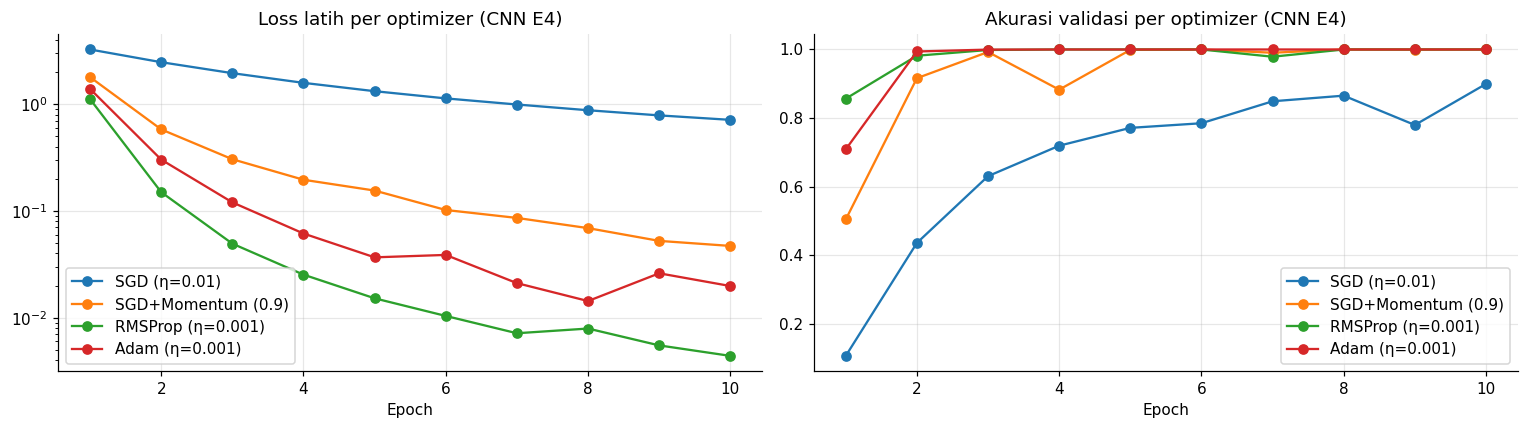

In [42]:
OPT_EPOCHS = 2 if QUICK_MODE else 10
opt_cfg = {
    "SGD (η=0.01)":           lambda: keras.optimizers.SGD(0.01),
    "SGD+Momentum (0.9)":     lambda: keras.optimizers.SGD(0.01, momentum=0.9),
    "RMSProp (η=0.001)":      lambda: keras.optimizers.RMSprop(1e-3),
    "Adam (η=0.001)":         lambda: keras.optimizers.Adam(1e-3),
}
for name, make_opt in opt_cfg.items():
    keras.utils.set_random_seed(SEED)
    m = build_cnn_reg(name="opt_study")
    m.compile(optimizer=make_opt(), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(train_ds, validation_data=val_ds, epochs=OPT_EPOCHS, verbose=0)
    _, ta = m.evaluate(test_ds, verbose=0)
    R["optimizer"][name] = {"val_acc": [float(v) for v in h.history["val_accuracy"]],
                            "val_loss": [float(v) for v in h.history["val_loss"]],
                            "train_loss": [float(v) for v in h.history["loss"]],
                            "test_acc": float(ta), "time_s": time.time() - t0}
    print(f"{name:<22} val_loss akhir {h.history['val_loss'][-1]:.4f} | val_acc {h.history['val_accuracy'][-1]:.4f} | test {ta:.4f} | {time.time()-t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, r in R["optimizer"].items():
    ax[0].plot(range(1, len(r["train_loss"]) + 1), r["train_loss"], "o-", label=name)
    ax[1].plot(range(1, len(r["val_acc"]) + 1), r["val_acc"], "o-", label=name)
ax[0].set_title("Loss latih per optimizer (CNN E4)"); ax[0].set_yscale("log")
ax[1].set_title("Akurasi validasi per optimizer (CNN E4)")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); savefig("fig_optimizer"); plt.show()

## 10. Eksperimen Iteratif E1 → E5 (Iterasi Perbaikan Model)
Setiap iterasi menjawab kelemahan iterasi sebelumnya:
* **E1 → E2**: MLP dasar mudah *overfit* dan lambat konvergen dengan SGD, sehingga ditambahkan BatchNorm, Dropout, Adam, dan *scheduler*.
* **E2 → E3**: MLP mengabaikan struktur spasial citra, sehingga diganti CNN.
* **E3 → E4**: CNN *baseline* masih *overfit*, sehingga ditambahkan blok konvolusi bertumpuk, BatchNorm, Dropout, dan ReduceLROnPlateau.
* **E4 → E5**: data uji berasal dari distribusi yang sedikit berbeda (posisi dan pencahayaan), sehingga ditambahkan augmentasi pada `tf.data`.


E1: MLP Baseline
Flatten-256-128-24 (ReLU), SGD lr=0.01, tanpa regularisasi, EarlyStopping saja
Parameter: 236,952
Epoch 1/30
194/194 - 3s - 15ms/step - accuracy: 0.1848 - loss: 2.9692 - val_accuracy: 0.1631 - val_loss: 2.8274 - lr: 0.0100
Epoch 2/30
194/194 - 1s - 5ms/step - accuracy: 0.3390 - loss: 2.5557 - val_accuracy: 0.2269 - val_loss: 2.5333 - lr: 0.0100
Epoch 3/30
194/194 - 1s - 5ms/step - accuracy: 0.4352 - loss: 2.1835 - val_accuracy: 0.1861 - val_loss: 2.4744 - lr: 0.0100
Epoch 4/30
194/194 - 1s - 6ms/step - accuracy: 0.5004 - loss: 1.8953 - val_accuracy: 0.2556 - val_loss: 2.1781 - lr: 0.0100
Epoch 5/30
194/194 - 1s - 4ms/step - accuracy: 0.5546 - loss: 1.6780 - val_accuracy: 0.3121 - val_loss: 2.0249 - lr: 0.0100
Epoch 6/30
194/194 - 1s - 6ms/step - accuracy: 0.5933 - loss: 1.5154 - val_accuracy: 0.2993 - val_loss: 2.3183 - lr: 0.0100
Epoch 7/30
194/194 - 1s - 4ms/step - accuracy: 0.6262 - loss: 1.3845 - val_accuracy: 0.3445 - val_loss: 1.9415 - lr: 0.0100
Epoch 8/30
194/

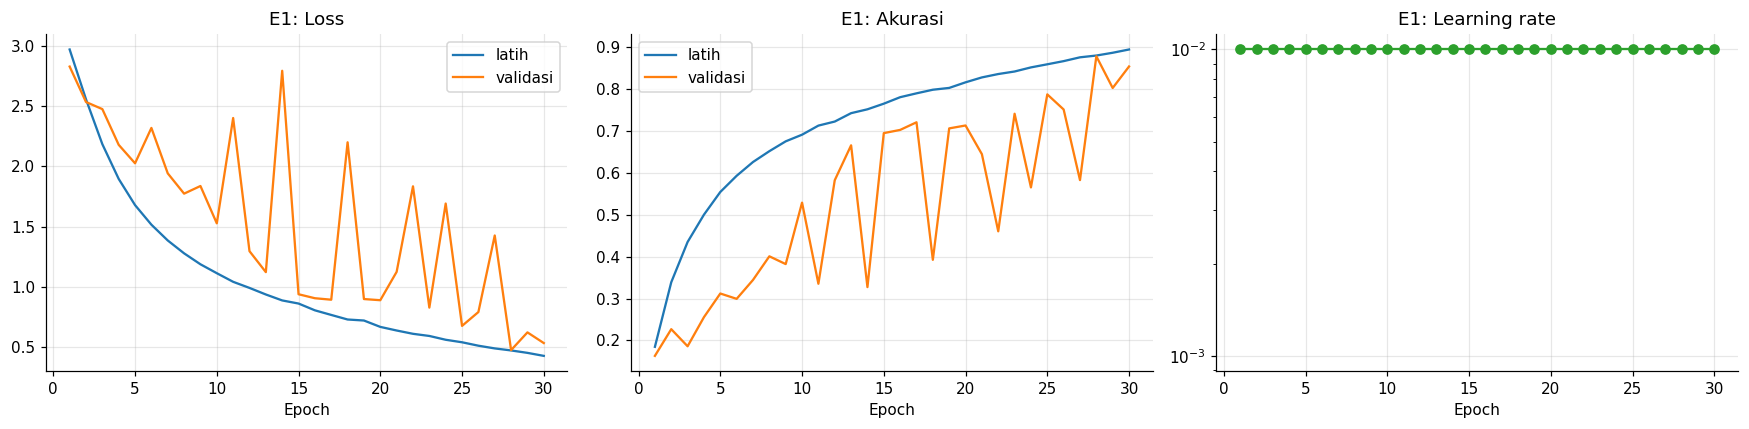

In [43]:
run_experiment("E1", "MLP Baseline", "Flatten-256-128-24 (ReLU), SGD lr=0.01, tanpa regularisasi, EarlyStopping saja",
               build_mlp_baseline(), keras.optimizers.SGD(0.01), train_ds, epochs=30, patience=5,
               reduce_lr=False, opt_name="SGD (0.01)")
plot_history("E1", "fig_hist_E1")


E2: MLP + BatchNorm + Dropout + Adam
Flatten-512-256-128-24, BN + Dropout 0.3, Adam 1e-3, ReduceLROnPlateau, EarlyStopping
Parameter: 571,928
Epoch 1/40
194/194 - 12s - 62ms/step - accuracy: 0.5930 - loss: 1.4348 - val_accuracy: 0.5211 - val_loss: 1.7230 - lr: 0.0010 - learning_rate: 0.0010
Epoch 2/40
194/194 - 1s - 6ms/step - accuracy: 0.8952 - loss: 0.3956 - val_accuracy: 0.6613 - val_loss: 1.0839 - lr: 0.0010 - learning_rate: 0.0010
Epoch 3/40
194/194 - 1s - 5ms/step - accuracy: 0.9509 - loss: 0.1885 - val_accuracy: 0.5783 - val_loss: 1.5241 - lr: 0.0010 - learning_rate: 0.0010
Epoch 4/40
194/194 - 1s - 5ms/step - accuracy: 0.9423 - loss: 0.2005 - val_accuracy: 0.6537 - val_loss: 1.1325 - lr: 0.0010 - learning_rate: 0.0010
Epoch 5/40
194/194 - 1s - 4ms/step - accuracy: 0.9657 - loss: 0.1245 - val_accuracy: 0.6784 - val_loss: 0.9999 - lr: 0.0010 - learning_rate: 0.0010
Epoch 6/40
194/194 - 1s - 4ms/step - accuracy: 0.9798 - loss: 0.0752 - val_accuracy: 0.4548 - val_loss: 2.4181 - lr

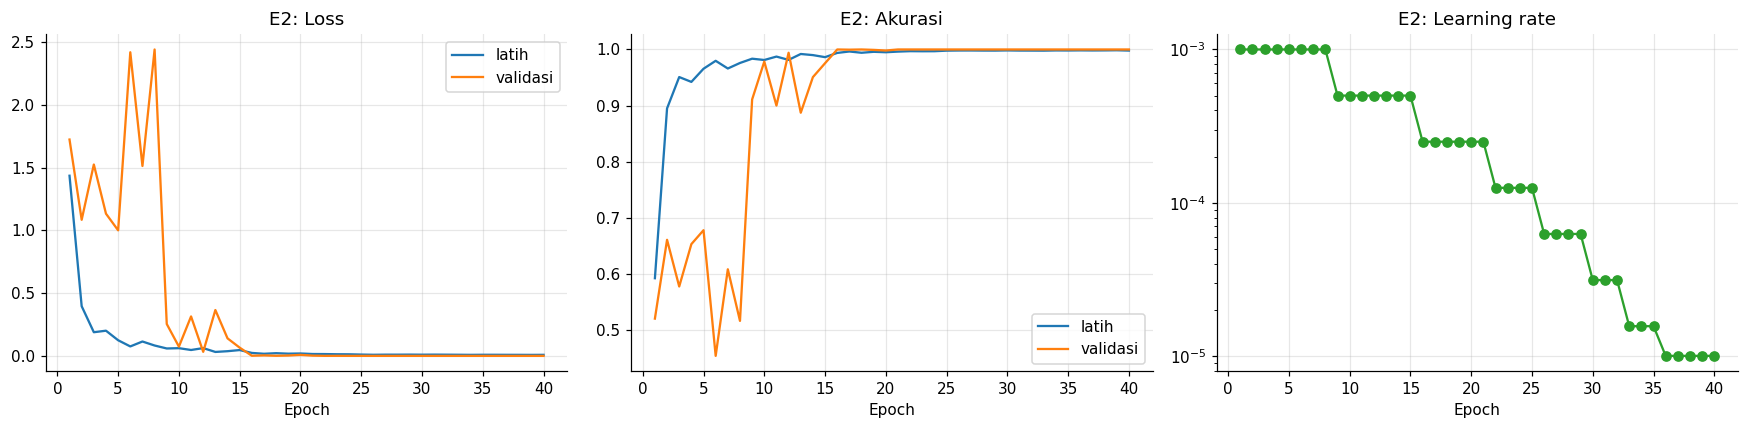

In [44]:
run_experiment("E2", "MLP + BatchNorm + Dropout + Adam", "Flatten-512-256-128-24, BN + Dropout 0.3, Adam 1e-3, ReduceLROnPlateau, EarlyStopping",
               build_mlp_reg(), keras.optimizers.Adam(1e-3), train_ds, epochs=40, patience=8,
               reduce_lr=True, opt_name="Adam (1e-3)")
plot_history("E2", "fig_hist_E2")


E3: CNN Baseline
Conv32-Pool-Conv64-Pool-Dense128-24, Adam 1e-3, tanpa BN/Dropout, EarlyStopping
Parameter: 423,448
Epoch 1/30
194/194 - 11s - 58ms/step - accuracy: 0.5333 - loss: 1.6533 - val_accuracy: 0.7983 - val_loss: 0.6018 - lr: 0.0010
Epoch 2/30
194/194 - 1s - 6ms/step - accuracy: 0.9328 - loss: 0.2693 - val_accuracy: 0.9782 - val_loss: 0.1295 - lr: 0.0010
Epoch 3/30
194/194 - 1s - 6ms/step - accuracy: 0.9910 - loss: 0.0727 - val_accuracy: 0.9945 - val_loss: 0.0451 - lr: 0.0010
Epoch 4/30
194/194 - 1s - 6ms/step - accuracy: 0.9996 - loss: 0.0214 - val_accuracy: 1.0000 - val_loss: 0.0147 - lr: 0.0010
Epoch 5/30
194/194 - 1s - 7ms/step - accuracy: 0.9999 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 0.0081 - lr: 0.0010
Epoch 6/30
194/194 - 1s - 7ms/step - accuracy: 0.9999 - loss: 0.0055 - val_accuracy: 1.0000 - val_loss: 0.0055 - lr: 0.0010
Epoch 7/30
194/194 - 1s - 7ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 1.0000 - val_loss: 0.0037 - lr: 0.0010
Epoch 8/30
19

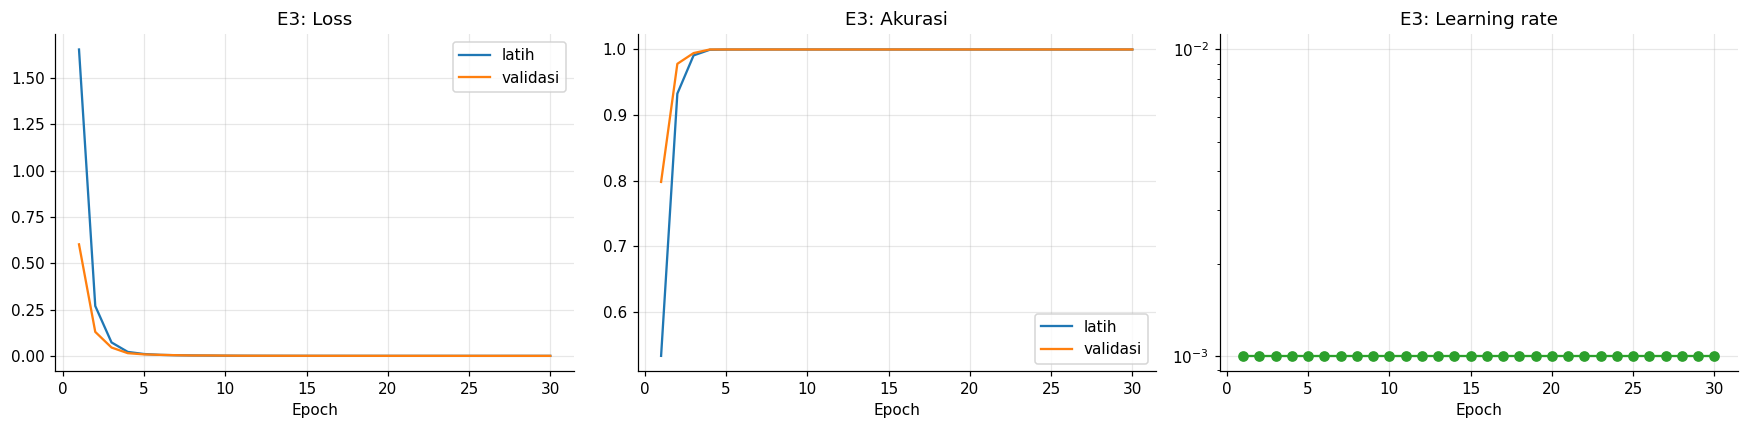

In [45]:
run_experiment("E3", "CNN Baseline", "Conv32-Pool-Conv64-Pool-Dense128-24, Adam 1e-3, tanpa BN/Dropout, EarlyStopping",
               build_cnn_baseline(), keras.optimizers.Adam(1e-3), train_ds, epochs=30, patience=5,
               reduce_lr=False, opt_name="Adam (1e-3)")
plot_history("E3", "fig_hist_E3")


E4: CNN + BatchNorm + Dropout
3 blok Conv (32-32/64-64/128) + BN + Dropout, Dense256, Adam 1e-3, ReduceLROnPlateau, EarlyStopping
Parameter: 441,912
Epoch 1/40
194/194 - 18s - 91ms/step - accuracy: 0.5852 - loss: 1.3853 - val_accuracy: 0.6854 - val_loss: 1.0788 - lr: 0.0010 - learning_rate: 0.0010
Epoch 2/40
194/194 - 2s - 13ms/step - accuracy: 0.9147 - loss: 0.3021 - val_accuracy: 0.9905 - val_loss: 0.0895 - lr: 0.0010 - learning_rate: 0.0010
Epoch 3/40
194/194 - 2s - 13ms/step - accuracy: 0.9721 - loss: 0.1164 - val_accuracy: 0.9996 - val_loss: 0.0104 - lr: 0.0010 - learning_rate: 0.0010
Epoch 4/40
194/194 - 2s - 12ms/step - accuracy: 0.9866 - loss: 0.0636 - val_accuracy: 1.0000 - val_loss: 0.0039 - lr: 0.0010 - learning_rate: 0.0010
Epoch 5/40
194/194 - 2s - 12ms/step - accuracy: 0.9932 - loss: 0.0350 - val_accuracy: 1.0000 - val_loss: 0.0018 - lr: 0.0010 - learning_rate: 0.0010
Epoch 6/40
194/194 - 2s - 12ms/step - accuracy: 0.9938 - loss: 0.0302 - val_accuracy: 1.0000 - val_loss:

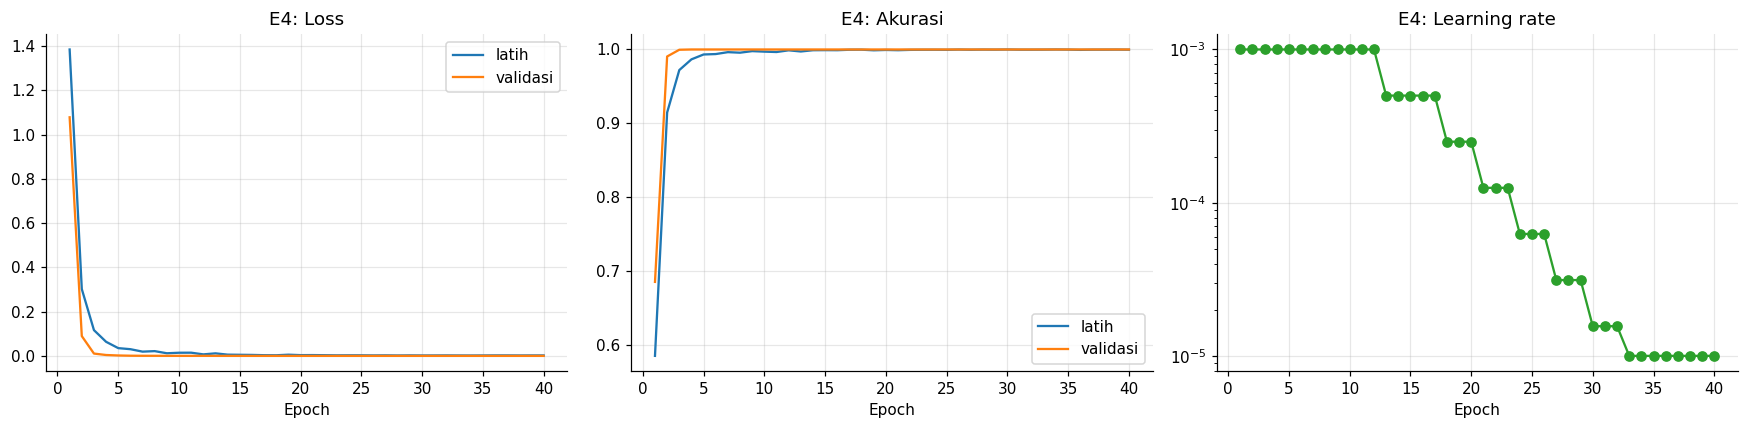

In [46]:
run_experiment("E4", "CNN + BatchNorm + Dropout", "3 blok Conv (32-32/64-64/128) + BN + Dropout, Dense256, Adam 1e-3, ReduceLROnPlateau, EarlyStopping",
               build_cnn_reg("E4_CNN_Reg"), keras.optimizers.Adam(1e-3), train_ds, epochs=40, patience=8,
               reduce_lr=True, opt_name="Adam (1e-3)")
plot_history("E4", "fig_hist_E4")


E5: CNN + BatchNorm + Dropout + Augmentasi (model akhir)
Arsitektur E4 + augmentasi tf.data (rotasi, zoom, translasi, brightness, contrast)
Parameter: 441,912
Epoch 1/50
194/194 - 18s - 94ms/step - accuracy: 0.3809 - loss: 2.0388 - val_accuracy: 0.6001 - val_loss: 1.2307 - lr: 0.0010 - learning_rate: 0.0010
Epoch 2/50
194/194 - 5s - 24ms/step - accuracy: 0.7428 - loss: 0.7925 - val_accuracy: 0.8911 - val_loss: 0.3537 - lr: 0.0010 - learning_rate: 0.0010
Epoch 3/50
194/194 - 3s - 17ms/step - accuracy: 0.8572 - loss: 0.4444 - val_accuracy: 0.8988 - val_loss: 0.3082 - lr: 0.0010 - learning_rate: 0.0010
Epoch 4/50
194/194 - 3s - 16ms/step - accuracy: 0.9133 - loss: 0.2753 - val_accuracy: 0.9603 - val_loss: 0.1360 - lr: 0.0010 - learning_rate: 0.0010
Epoch 5/50
194/194 - 3s - 16ms/step - accuracy: 0.9374 - loss: 0.2010 - val_accuracy: 0.9854 - val_loss: 0.0700 - lr: 0.0010 - learning_rate: 0.0010
Epoch 6/50
194/194 - 5s - 26ms/step - accuracy: 0.9513 - loss: 0.1593 - val_accuracy: 0.9581 -

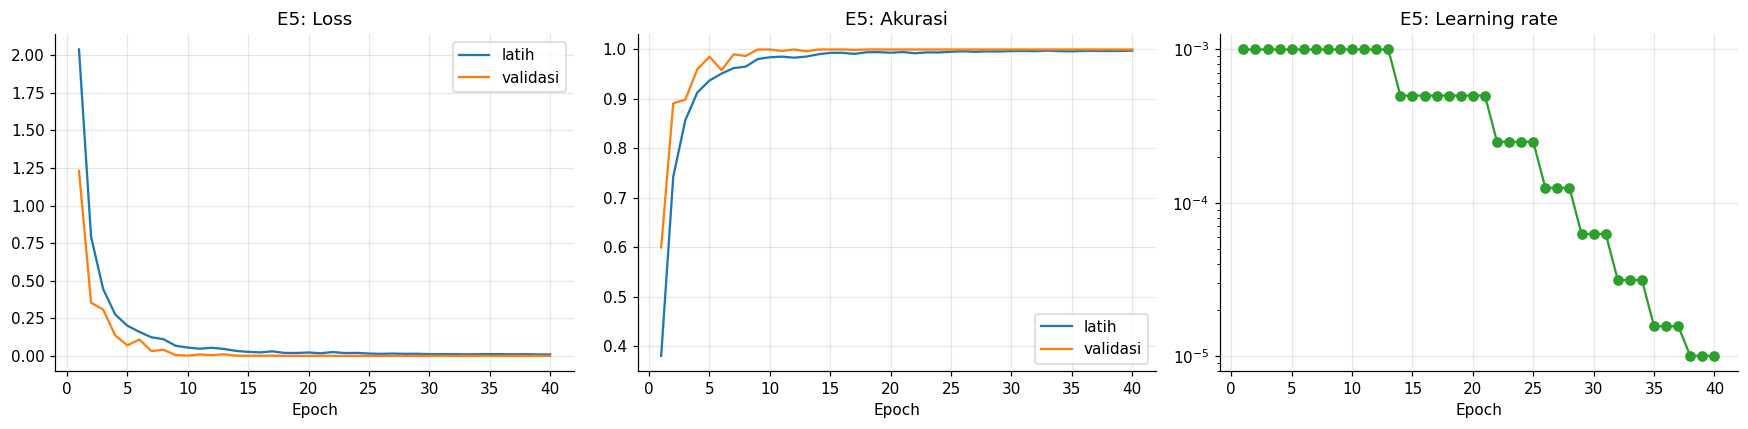

In [47]:
run_experiment("E5", "CNN + BatchNorm + Dropout + Augmentasi (model akhir)",
               "Arsitektur E4 + augmentasi tf.data (rotasi, zoom, translasi, brightness, contrast)",
               build_cnn_reg("E5_CNN_Reg_Aug"), keras.optimizers.Adam(1e-3), train_ds_aug, epochs=50, patience=10,
               reduce_lr=True, augment=True, opt_name="Adam (1e-3)")
plot_history("E5", "fig_hist_E5")

## 11. Ringkasan Seluruh Eksperimen
Tabel berikut adalah dokumentasi *hyperparameter* dan hasil setiap iterasi (langkah 7 RTM). Kolom **Gap** adalah selisih akurasi validasi dan uji. Nilai gap yang besar menunjukkan bahwa model belum bisa menggeneralisasi ke distribusi data uji.

id                                                 nama  params  epochs_run  best_epoch  train_time_s  train_acc  val_acc  test_acc  macro_f1  gap_val_test
E1                                         MLP Baseline  236952          30          28       27.3755     0.8805   0.8787    0.6799    0.6567        0.1989
E2                     MLP + BatchNorm + Dropout + Adam  571928          40          39       46.3326     0.9986   1.0000    0.8218    0.8059        0.1782
E3                                         CNN Baseline  423448          30          29       45.0577     1.0000   1.0000    0.9149    0.9032        0.0851
E4                            CNN + BatchNorm + Dropout  441912          40          40      114.2238     0.9997   1.0000    0.9994    0.9994        0.0006
E5 CNN + BatchNorm + Dropout + Augmentasi (model akhir)  441912          40          30      165.0394     0.9968   1.0000    1.0000    1.0000        0.0000
[gambar tersimpan] outputs/figures/fig_perbandingan_eksperimen.p

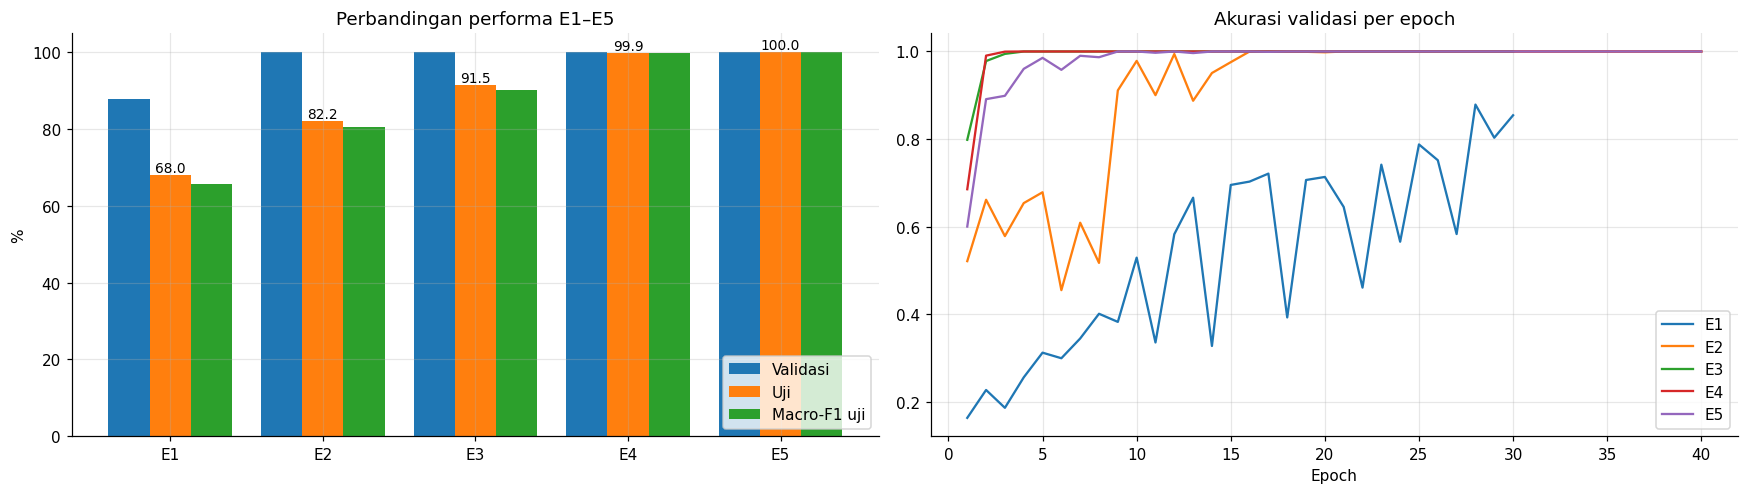

In [48]:
df_exp = pd.DataFrame([{k: e[k] for k in ["id", "nama", "optimizer", "augmentasi", "params", "epochs_run", "best_epoch",
                                           "train_time_s", "train_acc", "val_acc", "test_acc", "test_loss",
                                           "macro_p", "macro_r", "macro_f1"]} for e in R["experiments"]])
df_exp["gap_val_test"] = df_exp["val_acc"] - df_exp["test_acc"]
df_exp.to_csv(os.path.join(OUT_DIR, "ringkasan_eksperimen.csv"), index=False)
display_cols = ["id", "nama", "params", "epochs_run", "best_epoch", "train_time_s", "train_acc", "val_acc", "test_acc", "macro_f1", "gap_val_test"]
print(df_exp[display_cols].to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
x = np.arange(len(df_exp)); wbar = 0.27
ax[0].bar(x - wbar, df_exp["val_acc"] * 100, wbar, label="Validasi")
ax[0].bar(x, df_exp["test_acc"] * 100, wbar, label="Uji")
ax[0].bar(x + wbar, df_exp["macro_f1"] * 100, wbar, label="Macro-F1 uji")
for i, v in enumerate(df_exp["test_acc"] * 100):
    ax[0].text(i, v + 0.8, f"{v:.1f}", ha="center", fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(df_exp["id"]); ax[0].set_ylim(0, 105); ax[0].set_ylabel("%")
ax[0].set_title("Perbandingan performa E1–E5"); ax[0].legend(loc="lower right")
for eid in df_exp["id"]:
    h = HIST[eid]; ax[1].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], label=eid)
ax[1].set_title("Akurasi validasi per epoch"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); savefig("fig_perbandingan_eksperimen"); plt.show()

## 12. Evaluasi Mendalam Model Akhir (E5) pada 7.172 Citra Uji Resmi
Metrik yang dihitung: *accuracy*, *precision*, *recall*, *F1-score* (*macro* dan *weighted*), *classification report* per huruf, *confusion matrix* 24×24 (dinormalisasi per baris), akurasi per kelas, pasangan huruf yang paling sering tertukar, distribusi *confidence*, dan latensi inferensi.

              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       331
           B     1.0000    1.0000    1.0000       432
           C     1.0000    1.0000    1.0000       310
           D     1.0000    1.0000    1.0000       245
           E     1.0000    1.0000    1.0000       498
           F     1.0000    1.0000    1.0000       247
           G     1.0000    1.0000    1.0000       348
           H     1.0000    1.0000    1.0000       436
           I     1.0000    1.0000    1.0000       288
           K     1.0000    1.0000    1.0000       331
           L     1.0000    1.0000    1.0000       209
           M     1.0000    1.0000    1.0000       394
           N     1.0000    1.0000    1.0000       291
           O     1.0000    1.0000    1.0000       246
           P     1.0000    1.0000    1.0000       347
           Q     1.0000    1.0000    1.0000       164
           R     1.0000    1.0000    1.0000       144
           S     1.0000    

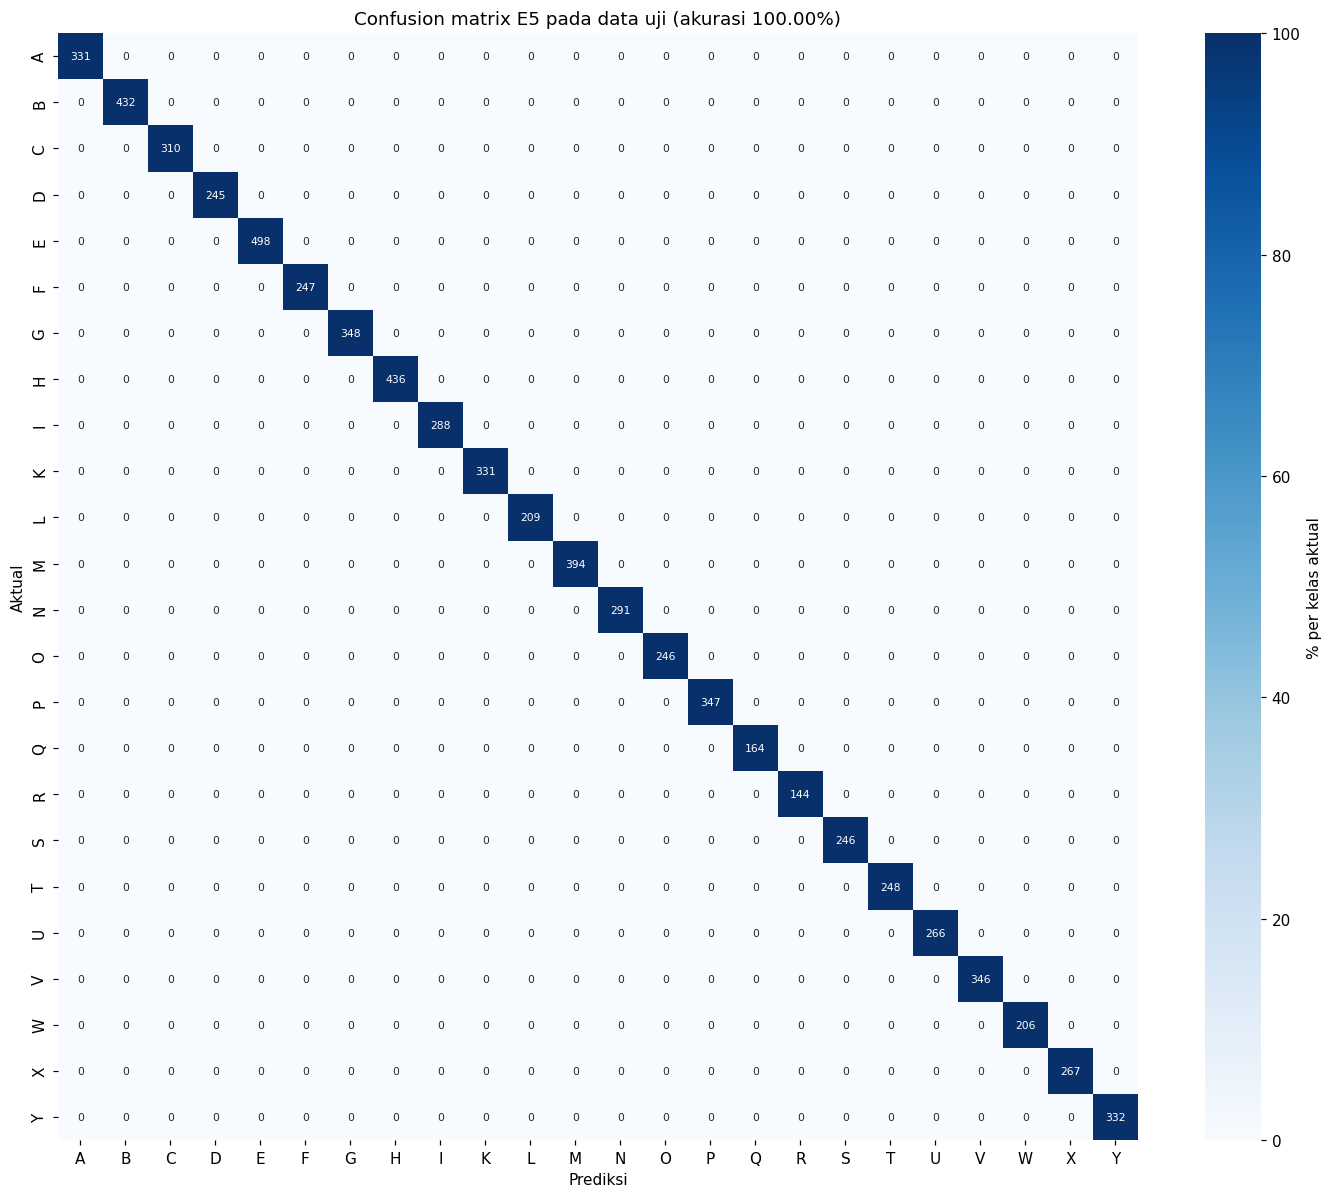

In [49]:
FINAL_ID = "E5"
final_model = MODELS[FINAL_ID]
prob_final = PROBS[FINAL_ID]
y_pred = prob_final.argmax(1)
conf = prob_final.max(1)
m_final = metrik(y_test, y_pred)
rep = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True, zero_division=0)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
pd.DataFrame(rep).T.to_csv(os.path.join(OUT_DIR, "classification_report_E5.csv"))

cm = confusion_matrix(y_test, y_pred, labels=range(N_CLASSES))
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm_norm * 100, annot=cm, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={"label": "% per kelas aktual"}, annot_kws={"size": 7}, ax=ax, vmin=0, vmax=100)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.grid(False)
ax.set_title(f"Confusion matrix {FINAL_ID} pada data uji (akurasi {m_final['acc']*100:.2f}%)")
plt.tight_layout(); savefig("fig_confusion_matrix"); plt.show()

[gambar tersimpan] outputs/figures/fig_akurasi_per_kelas.png


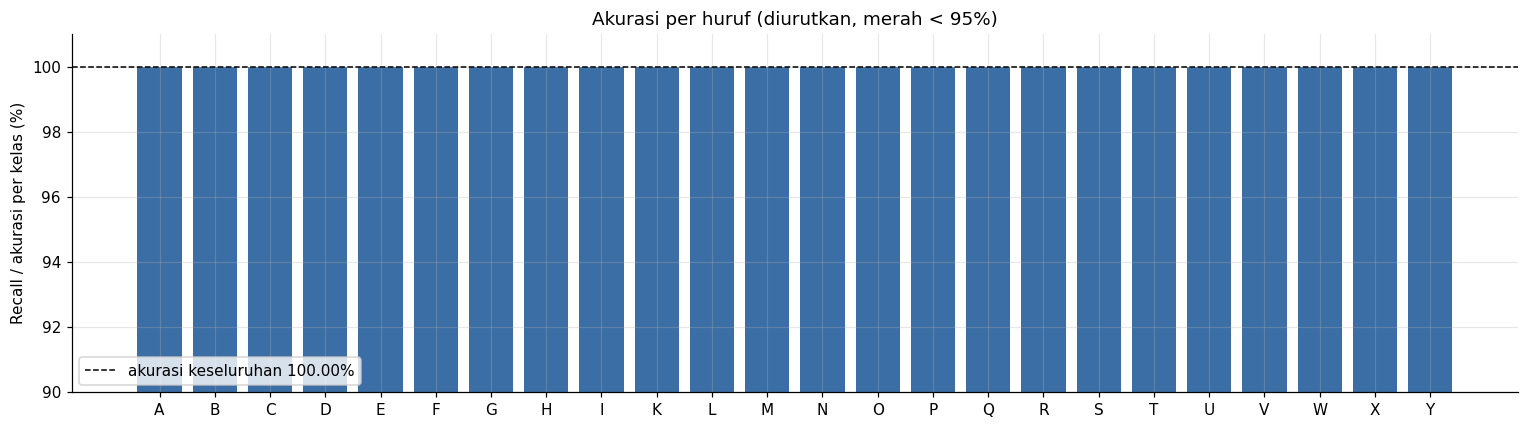

10 pasangan huruf yang paling sering tertukar (aktual -> prediksi):


In [50]:
per_class_acc = cm.diagonal() / cm.sum(1)
order = np.argsort(per_class_acc)
plt.figure(figsize=(14, 4))
bars = plt.bar([CLASS_NAMES[i] for i in order], per_class_acc[order] * 100,
               color=["#c0392b" if per_class_acc[i] < 0.95 else "#3b6ea5" for i in order])
plt.axhline(m_final["acc"] * 100, ls="--", c="k", lw=1, label=f"akurasi keseluruhan {m_final['acc']*100:.2f}%")
plt.ylabel("Recall / akurasi per kelas (%)"); plt.title("Akurasi per huruf (diurutkan, merah < 95%)")
plt.ylim(max(0, per_class_acc.min() * 100 - 10), 101); plt.legend()
plt.tight_layout(); savefig("fig_akurasi_per_kelas"); plt.show()

pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])[:10]
print("10 pasangan huruf yang paling sering tertukar (aktual -> prediksi):")
for k, (a, p, n) in enumerate(pairs, 1):
    print(f"{k:>2}. {a} -> {p}: {n} citra ({n / cm[CLASS_NAMES.index(a)].sum() * 100:.1f}% dari kelas {a})")

[gambar tersimpan] outputs/figures/fig_confidence.png


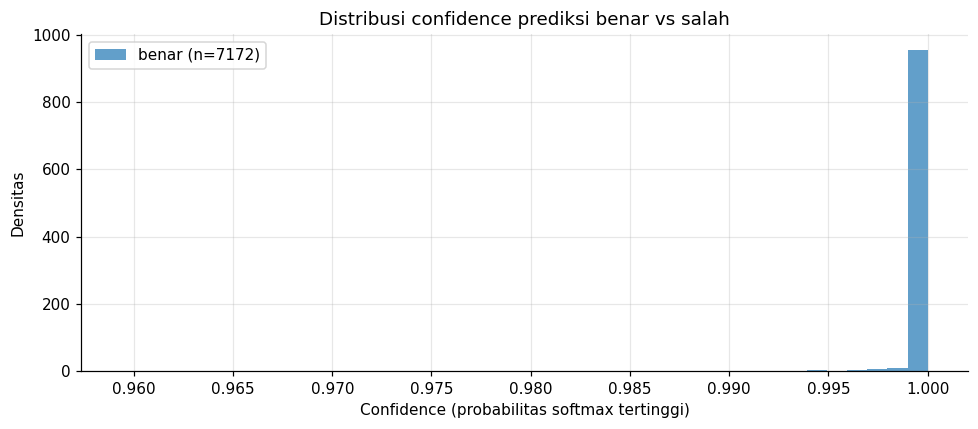

Akurasi uji 100.00% | Macro-F1 100.00% | benar 7172/7172
Latensi: 19.52 ms/citra (tunggal) | 0.037 ms/citra (batch)


In [51]:
wrong = np.where(y_pred != y_test)[0]
n_show = min(24, len(wrong))
if n_show:
    pick = wrong[np.argsort(-conf[wrong])][:n_show]          # salah dengan confidence tertinggi
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, pick):
        ax.imshow(X_test[i, ..., 0], cmap="gray")
        ax.set_title(f"A:{CLASS_NAMES[y_test[i]]}  P:{CLASS_NAMES[y_pred[i]]}\n{conf[i]*100:.0f}%", fontsize=9, color="#c0392b")
    plt.suptitle("Contoh salah klasifikasi (A = aktual, P = prediksi, % = confidence)", fontsize=13)
    plt.tight_layout(); savefig("fig_salah_klasifikasi"); plt.show()

plt.figure(figsize=(9, 4))
plt.hist(conf[y_pred == y_test], bins=40, alpha=0.7, label=f"benar (n={int((y_pred == y_test).sum())})", density=True)
if len(wrong): plt.hist(conf[wrong], bins=40, alpha=0.7, label=f"salah (n={len(wrong)})", density=True)
plt.xlabel("Confidence (probabilitas softmax tertinggi)"); plt.ylabel("Densitas"); plt.legend()
plt.title("Distribusi confidence prediksi benar vs salah"); plt.tight_layout(); savefig("fig_confidence"); plt.show()

# Latensi inferensi
one = tf.convert_to_tensor(X_test[:1])
for _ in range(5): final_model(one, training=False)
t0 = time.time()
for _ in range(100): final_model(one, training=False)
lat_single = (time.time() - t0) / 100 * 1000
t0 = time.time(); final_model.predict(test_ds, verbose=0); lat_batch = (time.time() - t0) / len(X_test) * 1000

R["final"] = {"id": FINAL_ID, **m_final,
              "test_loss": next(e["test_loss"] for e in R["experiments"] if e["id"] == FINAL_ID),
              "n_test": int(len(y_test)), "n_benar": int((y_pred == y_test).sum()), "n_salah": int(len(wrong)),
              "mean_conf_benar": float(conf[y_pred == y_test].mean()),
              "mean_conf_salah": float(conf[wrong].mean()) if len(wrong) else None,
              "per_class": {c: {"precision": rep[c]["precision"], "recall": rep[c]["recall"],
                                "f1": rep[c]["f1-score"], "support": int(rep[c]["support"])} for c in CLASS_NAMES},
              "top_confusions": pairs, "latency_single_ms": lat_single, "latency_batch_ms": lat_batch,
              "confusion_matrix": cm.tolist()}
print(f"Akurasi uji {m_final['acc']*100:.2f}% | Macro-F1 {m_final['macro_f1']*100:.2f}% | benar {R['final']['n_benar']}/{len(y_test)}")
print(f"Latensi: {lat_single:.2f} ms/citra (tunggal) | {lat_batch:.3f} ms/citra (batch)")

## 13. Fitur Unik 1: *Confidence Threshold* dan Deteksi Input di Luar Domain (OOD)
**Apa**: setiap prediksi hanya **diterima** jika probabilitas *softmax* tertingginya ≥ ambang τ. Jika di bawah τ, aplikasi menjawab "tidak yakin / bukan isyarat huruf ASL" alih-alih memaksakan satu huruf.

**Mengapa**: di aplikasi nyata pengguna bisa mengunggah foto apa saja (wajah, benda, foto buram). Model *softmax* selalu menghasilkan salah satu dari 24 huruf, sehingga tanpa mekanisme penolakan kesalahan semacam ini tidak terlihat.

**Bagaimana**: τ ditentukan **tanpa menyentuh data uji**. Data validasi diaugmentasi untuk mensimulasikan pergeseran distribusi, lalu dipilih τ terkecil yang membuat akurasi prediksi yang diterima ≥ `TARGET_ACC_DITERIMA`, dengan batas bawah τ = 0,5. Dampaknya diukur pada data uji (*coverage* dan akurasi prediksi yang diterima) dan pada empat set OOD (derau, citra polos, digit MNIST, Fashion-MNIST).

In [52]:
from sklearn.metrics import roc_auc_score
TAU_MIN = 0.50
keras.utils.set_random_seed(SEED)
val_aug_ds = make_dataset(X_val, y_val, augment=True)            # validasi teraugmentasi (tanpa shuffle)
prob_va = final_model.predict(val_aug_ds, verbose=0)
conf_va, pred_va = prob_va.max(1), prob_va.argmax(1)

def akurasi_coverage(conf, pred, y, t):
    m = conf >= t
    return ((pred[m] == y[m]).mean() if m.any() else np.nan), m.mean()

grid = np.round(np.arange(0.0, 1.0, 0.01), 2)
TAU = None
for t in grid:
    a, c = akurasi_coverage(conf_va, pred_va, y_val, t)
    if a >= TARGET_ACC_DITERIMA:
        TAU = float(t); break
TAU = max(TAU if TAU is not None else 0.90, TAU_MIN)
va_acc, va_cov = akurasi_coverage(conf_va, pred_va, y_val, TAU)
print(f"Akurasi validasi teraugmentasi (tanpa ambang): {(pred_va == y_val).mean():.4f}")
print(f"Ambang terpilih τ = {TAU:.2f} -> akurasi diterima {va_acc:.4f}, coverage {va_cov:.4f} (validasi teraugmentasi)")

# Dampak pada data uji
conf_te, pred_te = prob_final.max(1), prob_final.argmax(1)
salah = pred_te != y_test
diterima = conf_te >= TAU
f1_res = {"tau": TAU, "tau_min": TAU_MIN, "target_acc": TARGET_ACC_DITERIMA,
          "val_aug_acc": float((pred_va == y_val).mean()), "val_aug_acc_diterima": float(va_acc), "val_aug_coverage": float(va_cov),
          "test": {"acc_tanpa": float((~salah).mean()), "acc_diterima": float((~salah[diterima]).mean()),
                   "coverage": float(diterima.mean()), "n_ditolak": int((~diterima).sum()),
                   "n_salah": int(salah.sum()), "salah_ditolak": int((salah & ~diterima).sum()),
                   "benar_ditolak": int((~salah & ~diterima).sum())}}
t_ = f1_res["test"]
print(f"\nData uji: akurasi tanpa ambang {t_['acc_tanpa']:.4f} | akurasi prediksi diterima {t_['acc_diterima']:.4f} | coverage {t_['coverage']:.4f}")
print(f"Kesalahan yang berhasil ditolak: {t_['salah_ditolak']}/{t_['n_salah']} | prediksi benar yang ikut ditolak: {t_['benar_ditolak']}")

# Set data di luar domain (OOD)
rng_ood = np.random.default_rng(SEED); N_OOD = 1000
ood_sets = {"Derau Gaussian": np.clip(rng_ood.normal(0.5, 0.25, (N_OOD, 28, 28, 1)), 0, 1).astype("float32"),
            "Citra polos": (np.ones((N_OOD, 28, 28, 1)) * rng_ood.uniform(0, 1, (N_OOD, 1, 1, 1))).astype("float32")}
for nama_ds, loader in [("Digit MNIST", keras.datasets.mnist), ("Fashion-MNIST", keras.datasets.fashion_mnist)]:
    try:
        (xo, _), _ = loader.load_data()
        ood_sets[nama_ds] = (xo[:N_OOD].astype("float32") / 255.0)[..., None]
    except Exception as e:
        print(f"{nama_ds} gagal diunduh ({repr(e)[:80]}); dilewati.")

f1_res["ood"] = {}
ood_conf = {}
for nama_ds, Xo in ood_sets.items():
    co = final_model.predict(Xo, batch_size=256, verbose=0).max(1)
    ood_conf[nama_ds] = co
    auroc = roc_auc_score(np.r_[np.ones(len(conf_te)), np.zeros(len(co))], np.r_[conf_te, co])
    f1_res["ood"][nama_ds] = {"n": int(len(co)), "ditolak": float((co < TAU).mean()),
                              "mean_conf": float(co.mean()), "auroc": float(auroc)}
    print(f"OOD {nama_ds:<15}: ditolak {(co < TAU).mean()*100:5.1f}% | rata-rata confidence {co.mean():.3f} | AUROC {auroc:.3f}")
R["fitur1"] = f1_res

Akurasi validasi teraugmentasi (tanpa ambang): 1.0000
Ambang terpilih τ = 0.50 -> akurasi diterima 1.0000, coverage 1.0000 (validasi teraugmentasi)

Data uji: akurasi tanpa ambang 1.0000 | akurasi prediksi diterima 1.0000 | coverage 1.0000
Kesalahan yang berhasil ditolak: 0/0 | prediksi benar yang ikut ditolak: 0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
OOD Derau Gaussian : ditolak   0.0% | rata-rata confidence 0.998 | AUROC 0.810
OOD Citra polos    : ditolak  10.8% | rata-rata confidence 0.643 | AUROC 1.000
OOD Digit MNIST    : ditolak   7.0% | rata-rata confidence 0.836 | AUROC 0.990
OOD Fashion-MNIST  : ditolak   5.4% | rata-rata confidence 0.855 | AUROC 0.977


[gambar tersimpan] outputs/figures/fig_fitur1_threshold.png


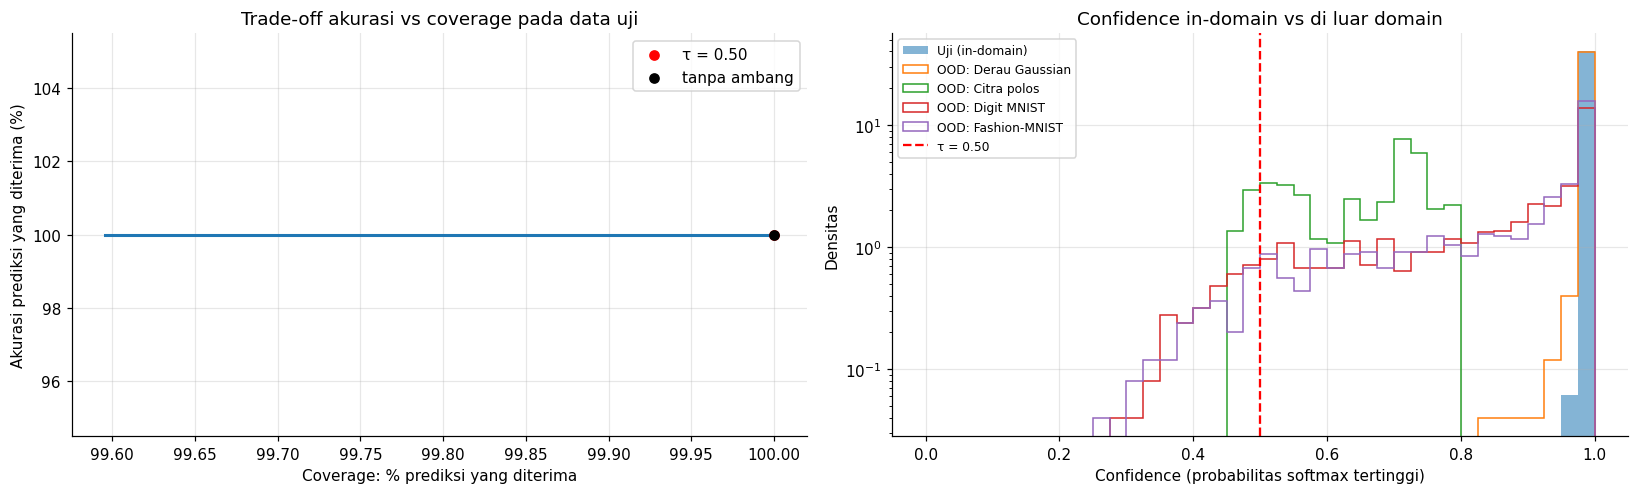

[gambar tersimpan] outputs/figures/fig_fitur1_ood_contoh.png


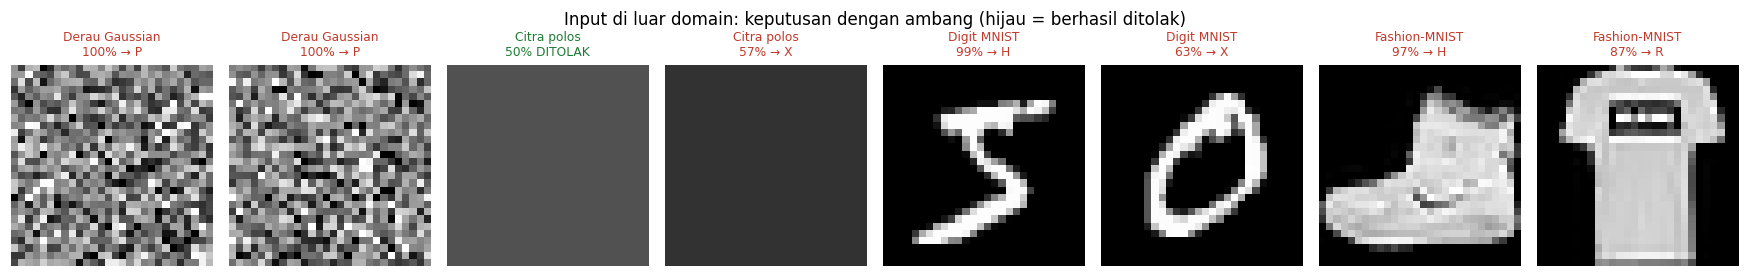

In [53]:
# Grafik dampak fitur 1: kurva akurasi-coverage di data uji dan distribusi confidence in-domain vs OOD
accs, covs = zip(*[akurasi_coverage(conf_te, pred_te, y_test, t) for t in grid])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(np.array(covs) * 100, np.array(accs) * 100, "-", lw=2)
ax[0].scatter([t_["coverage"] * 100], [t_["acc_diterima"] * 100], c="red", zorder=5, label=f"τ = {TAU:.2f}")
ax[0].scatter([100], [t_["acc_tanpa"] * 100], c="k", zorder=5, label="tanpa ambang")
ax[0].set_xlabel("Coverage: % prediksi yang diterima"); ax[0].set_ylabel("Akurasi prediksi yang diterima (%)")
ax[0].set_title("Trade-off akurasi vs coverage pada data uji"); ax[0].legend()
bins = np.linspace(0, 1, 41)
ax[1].hist(conf_te, bins=bins, density=True, alpha=0.55, label="Uji (in-domain)")
for nama_ds, co in ood_conf.items():
    ax[1].hist(co, bins=bins, density=True, histtype="step", lw=2, label=f"OOD: {nama_ds}")
ax[1].axvline(TAU, c="red", ls="--", label=f"τ = {TAU:.2f}")
ax[1].set_xlabel("Confidence (probabilitas softmax tertinggi)"); ax[1].set_ylabel("Densitas"); ax[1].set_yscale("log")
ax[1].set_title("Confidence in-domain vs di luar domain"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("fig_fitur1_threshold"); plt.show()

# Contoh input OOD beserta keputusan model
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
contoh = [(n, Xo[i]) for n, Xo in ood_sets.items() for i in range(2)][:8]
for ax, (n, xo) in zip(axes, contoh):
    p = final_model.predict(xo[None], verbose=0)[0]; c = p.max()
    ax.imshow(xo[..., 0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
    keputusan = "DITOLAK" if c < TAU else f"→ {CLASS_NAMES[p.argmax()]}"
    ax.set_title(f"{n}\n{c*100:.0f}% {keputusan}", fontsize=8, color="#c0392b" if c >= TAU else "#1e7b34")
plt.suptitle("Input di luar domain: keputusan dengan ambang (hijau = berhasil ditolak)", fontsize=11)
plt.tight_layout(); savefig("fig_fitur1_ood_contoh"); plt.show()

## 14. Fitur Unik 2: Kompresi Model ke TensorFlow Lite
**Apa**: model akhir dikonversi ke format **TensorFlow Lite** dalam empat varian, yaitu FP32, FP16, *dynamic range* (bobot INT8), dan *full integer* INT8 (kalibrasi dengan *representative dataset*).

**Mengapa**: aplikasi web dan perangkat seluler membutuhkan model yang kecil, cepat dimuat, dan tidak bergantung pada TensorFlow penuh (cukup *runtime* LiteRT yang ringan).

**Bagaimana**: model diekspor (`model.export`) ke SavedModel lalu dikonversi dengan `TFLiteConverter`. **Bukti dampaknya** diukur dari ukuran berkas, akurasi pada seluruh data uji, kesesuaian prediksi dengan model Keras, dan latensi per citra. Varian terkecil yang akurasinya turun ≤ 0,2 poin dipakai untuk deployment.

Saved artifact at 'outputs/models/saved_model_export'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_271')
Output Type:
  TensorSpec(shape=(None, 24), dtype=tf.float32, name=None)
Captures:
  133527044716496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044472656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044472464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044456912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044469200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044004688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044468816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044469008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044007184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133527044457104: TensorSpec(shape=(), dtype=tf.resource, name=No

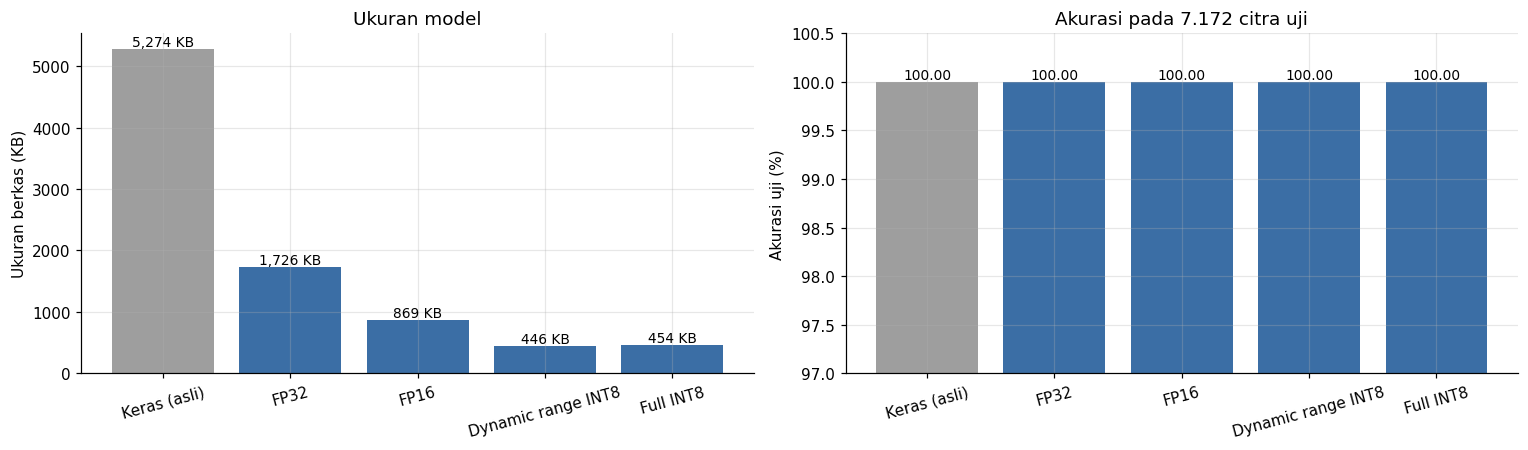

In [54]:
final_path = os.path.join(MODEL_DIR, f"{FINAL_ID}_model_akhir.keras")
final_model.save(final_path)
keras_kb = os.path.getsize(final_path) / 1024

def get_interpreter_cls():
    try:
        return tf.lite.Interpreter
    except AttributeError:
        pass
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "ai-edge-litert"], check=False)
        from ai_edge_litert.interpreter import Interpreter
    return Interpreter
Interpreter = get_interpreter_cls()

export_dir = os.path.join(MODEL_DIR, "saved_model_export")
try:
    final_model.export(export_dir)
    make_converter = lambda: tf.lite.TFLiteConverter.from_saved_model(export_dir)
except Exception as e:
    print("model.export gagal, memakai from_keras_model:", repr(e)[:120])
    make_converter = lambda: tf.lite.TFLiteConverter.from_keras_model(final_model)

def representative_data():
    for i in range(0, 300):
        yield [X_train[i:i + 1]]

def convert(varian):
    conv = make_converter()
    if varian == "FP16":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.target_spec.supported_types = [tf.float16]
    elif varian == "Dynamic range INT8":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
    elif varian == "Full INT8":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.representative_dataset = representative_data
    return conv.convert()

def tflite_predict(content, X, bs=256):
    itp = Interpreter(model_content=content)
    inp, out = itp.get_input_details()[0], itp.get_output_details()[0]
    itp.resize_tensor_input(inp["index"], [bs, 28, 28, 1]); itp.allocate_tensors()
    hasil = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]; nb = len(xb)
        if nb < bs:
            xb = np.concatenate([xb, np.zeros((bs - nb, 28, 28, 1), np.float32)])
        itp.set_tensor(inp["index"], xb.astype(np.float32)); itp.invoke()
        hasil.append(itp.get_tensor(out["index"])[:nb])
    return np.concatenate(hasil)

def tflite_latency(content, n=200):
    itp = Interpreter(model_content=content)
    inp, out = itp.get_input_details()[0], itp.get_output_details()[0]
    itp.resize_tensor_input(inp["index"], [1, 28, 28, 1]); itp.allocate_tensors()
    x1 = X_test[:1].astype(np.float32)
    for _ in range(10):
        itp.set_tensor(inp["index"], x1); itp.invoke()
    t0 = time.time()
    for _ in range(n):
        itp.set_tensor(inp["index"], x1); itp.invoke(); itp.get_tensor(out["index"])
    return (time.time() - t0) / n * 1000

TFLITE = {}
f2 = {"keras": {"size_kb": keras_kb, "test_acc": float(m_final["acc"]), "macro_f1": float(m_final["macro_f1"]),
                "latency_ms": float(lat_single), "agreement": 1.0}, "varian": {}}
for varian in ["FP32", "FP16", "Dynamic range INT8", "Full INT8"]:
    try:
        content = convert(varian)
        p = tflite_predict(content, X_test)
        yp = p.argmax(1)
        TFLITE[varian] = content
        f2["varian"][varian] = {"size_kb": len(content) / 1024, "test_acc": float(accuracy_score(y_test, yp)),
                                "macro_f1": float(f1_score(y_test, yp, average="macro")),
                                "agreement": float((yp == pred_te).mean()), "latency_ms": tflite_latency(content)}
        v = f2["varian"][varian]
        print(f"{varian:<20} {v['size_kb']:8.1f} KB | acc {v['test_acc']:.4f} | sama dgn Keras {v['agreement']*100:.2f}% | {v['latency_ms']:.3f} ms/citra")
    except Exception as e:
        print(f"{varian}: konversi/evaluasi gagal -> {repr(e)[:150]}")
print(f"{'Keras .keras (asli)':<20} {keras_kb:8.1f} KB | acc {m_final['acc']:.4f} | latensi Keras {lat_single:.3f} ms/citra")

kandidat = sorted(f2["varian"].items(), key=lambda kv: kv[1]["size_kb"])
DEPLOY_VARIANT = next((k for k, v in kandidat if v["test_acc"] >= m_final["acc"] - 0.002), "FP32" if "FP32" in TFLITE else None)
assert DEPLOY_VARIANT is not None, "Semua konversi TFLite gagal; periksa pesan error di atas."
f2["deploy_variant"] = DEPLOY_VARIANT
R["fitur2"] = f2
print("\nVarian untuk deployment:", DEPLOY_VARIANT)

nama = ["Keras (asli)"] + list(f2["varian"].keys())
ukuran = [keras_kb] + [v["size_kb"] for v in f2["varian"].values()]
akurasi = [m_final["acc"] * 100] + [v["test_acc"] * 100 for v in f2["varian"].values()]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(nama, ukuran, color=["#9e9e9e"] + ["#3b6ea5"] * (len(nama) - 1))
for i, v in enumerate(ukuran): ax[0].text(i, v, f"{v:,.0f} KB", ha="center", va="bottom", fontsize=9)
ax[0].set_ylabel("Ukuran berkas (KB)"); ax[0].set_title("Ukuran model"); ax[0].tick_params(axis="x", rotation=15)
ax[1].bar(nama, akurasi, color=["#9e9e9e"] + ["#3b6ea5"] * (len(nama) - 1))
for i, v in enumerate(akurasi): ax[1].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax[1].set_ylim(max(0, min(akurasi) - 3), 100.5); ax[1].set_ylabel("Akurasi uji (%)"); ax[1].set_title("Akurasi pada 7.172 citra uji")
ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); savefig("fig_fitur2_tflite"); plt.show()

## 15. Interpretasi dengan Grad-CAM
Grad-CAM (Selvaraju et al., 2017) menyorot area citra yang paling memengaruhi keputusan CNN. Heatmap dihitung dari gradien skor kelas terhadap *feature map* lapisan konvolusi terakhir (`b3c1_relu`, 7×7). Hasilnya dipakai untuk memeriksa apakah model memperhatikan bentuk jari, terutama pada prediksi yang salah.

[gambar tersimpan] outputs/figures/fig_gradcam.png


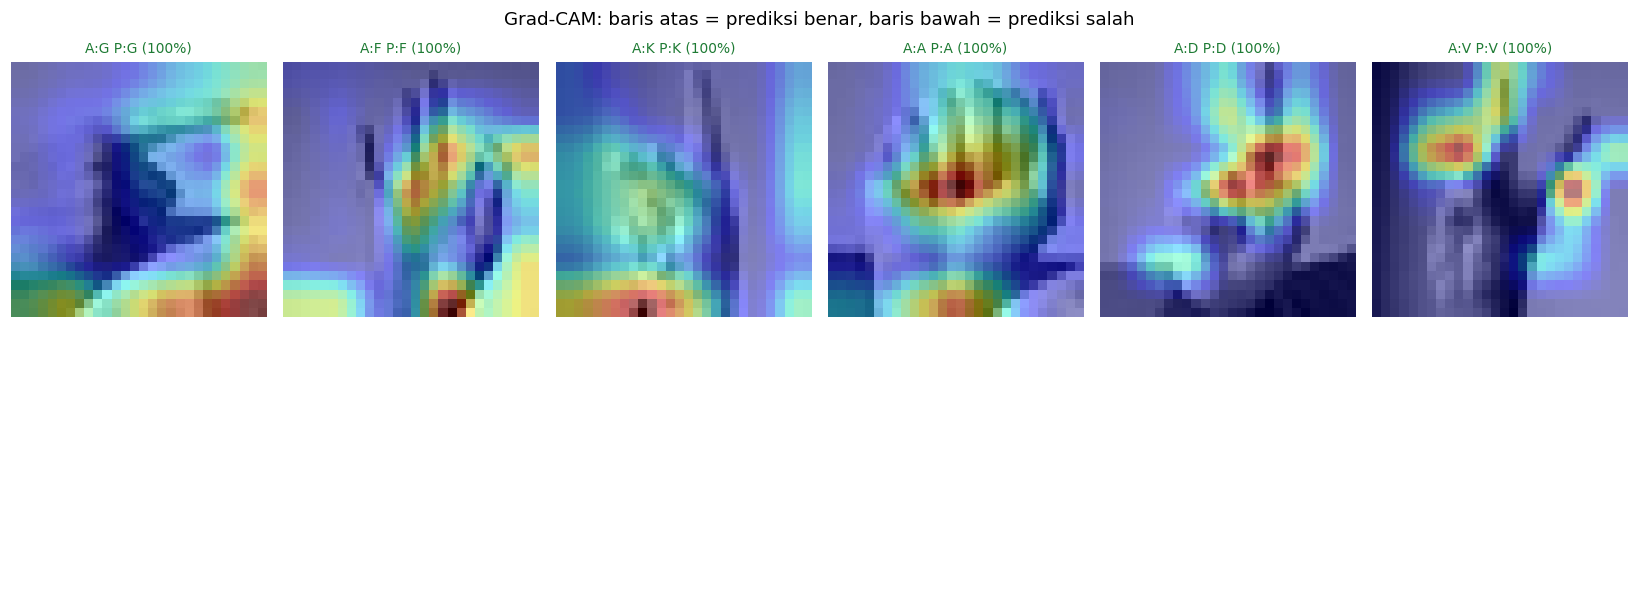

In [55]:
try:
    grad_model = keras.Model(final_model.inputs, [final_model.get_layer("b3c1_relu").output, final_model.outputs[0]])
    def gradcam(xb):
        xb = tf.convert_to_tensor(xb)
        with tf.GradientTape() as tape:
            conv, preds = grad_model(xb, training=False)
            kelas = tf.argmax(preds, axis=1)
            skor = tf.reduce_sum(preds * tf.one_hot(kelas, N_CLASSES), axis=1)
        grads = tape.gradient(skor, conv)
        bobot = tf.reduce_mean(grads, axis=(1, 2))
        cam = tf.nn.relu(tf.reduce_sum(conv * bobot[:, None, None, :], axis=-1)).numpy()
        cam = np.stack([cv2.resize(c / (c.max() + 1e-8), (28, 28), interpolation=cv2.INTER_LINEAR) for c in cam])
        return cam, preds.numpy()
    idx_benar = np.where(~salah)[0][:6]
    idx_salah = np.where(salah)[0][:6]
    idx = np.r_[idx_benar, idx_salah]
    cams, preds_gc = gradcam(X_test[idx])
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
    for ax, i, cam, pr in zip(axes.flat, idx, cams, preds_gc):
        ax.imshow(X_test[i, ..., 0], cmap="gray"); ax.imshow(cam, cmap="jet", alpha=0.45); ax.axis("off")
        ok = pr.argmax() == y_test[i]
        ax.set_title(f"A:{CLASS_NAMES[y_test[i]]} P:{CLASS_NAMES[pr.argmax()]} ({pr.max()*100:.0f}%)", fontsize=9,
                     color="#1e7b34" if ok else "#c0392b")
    for ax in axes.flat[len(idx):]: ax.axis("off")
    plt.suptitle("Grad-CAM: baris atas = prediksi benar, baris bawah = prediksi salah", fontsize=12)
    plt.tight_layout(); savefig("fig_gradcam"); plt.show()
    R["gradcam"] = {"ok": True, "layer": "b3c1_relu", "n_benar": int(len(idx_benar)), "n_salah": int(len(idx_salah))}
except Exception as e:
    print("Grad-CAM dilewati:", repr(e)[:200])
    R["gradcam"] = {"ok": False, "error": repr(e)[:200]}

## 16. Perbandingan dengan Proyek Sebelumnya
Proyek sebelumnya (notebook lama) memakai subset 1.200 citra dan diuji pada 240 citra. Angka di bawah diambil dari **output notebook lama**. Karena set ujinya berbeda (240 citra subset vs 7.172 citra uji resmi), perbandingan ini bersifat indikatif. Meski begitu, set uji baru 30 kali lebih besar sehingga hasilnya jauh lebih dapat dipercaya.

[gambar tersimpan] outputs/figures/fig_perbandingan_lama_baru.png


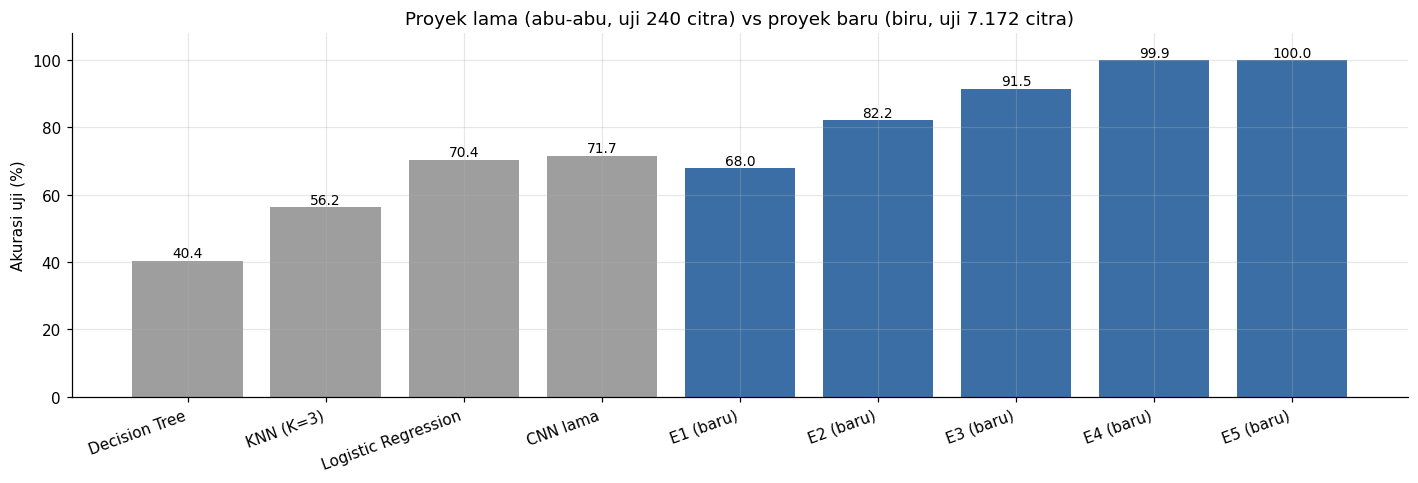

In [56]:
R["previous"] = {"catatan": "Output notebook lama: subset 1.200 citra, uji 240 citra",
                 "hasil": {"Decision Tree": 0.4042, "KNN (K=3)": 0.5625, "Logistic Regression": 0.7042, "CNN lama": 0.7167},
                 "cnn_lama_params": 906328, "laporan_lama_klaim_cnn": 0.9333}
labels = list(R["previous"]["hasil"].keys()) + [f"{e['id']} (baru)" for e in R["experiments"]]
vals = list(R["previous"]["hasil"].values()) + [e["test_acc"] for e in R["experiments"]]
colors = ["#9e9e9e"] * len(R["previous"]["hasil"]) + ["#3b6ea5"] * len(R["experiments"])
plt.figure(figsize=(13, 4.5))
plt.bar(labels, np.array(vals) * 100, color=colors)
for i, v in enumerate(vals): plt.text(i, v * 100 + 1, f"{v*100:.1f}", ha="center", fontsize=9)
plt.ylabel("Akurasi uji (%)"); plt.ylim(0, 108); plt.xticks(rotation=20, ha="right")
plt.title("Proyek lama (abu-abu, uji 240 citra) vs proyek baru (biru, uji 7.172 citra)")
plt.tight_layout(); savefig("fig_perbandingan_lama_baru"); plt.show()

## 17. Deployment: Aplikasi Gradio untuk Hugging Face Spaces
Folder `outputs/deploy/` berisi semua berkas aplikasi:

| Berkas | Isi |
|---|---|
| `model.tflite` | model hasil kompresi (fitur unik 2) |
| `config.json` | daftar label, ambang τ (fitur unik 1), dan info model |
| `inference.py` | praproses foto (grayscale → crop tengah → 28×28 → /255) dan prediksi dengan LiteRT |
| `app.py` | antarmuka Gradio: unggah/kamera, *slider* ambang, top-3, status diterima/ditolak, pratinjau 28×28 |
| `requirements.txt`, `README.md` | dependensi dan konfigurasi Space |
| `examples/` | contoh input untuk demo (prediksi benar, prediksi salah, dan input di luar domain) |

**Langkah deploy**: buat Space baru di huggingface.co (SDK **Gradio**), unggah seluruh isi `outputs/deploy/` (atau `git push`), lalu tunggu proses *build* selesai. Setelah itu, isi `LINK_APP` di sel konfigurasi.

In [57]:
DEPLOY_DIR = os.path.join(OUT_DIR, "deploy")
os.makedirs(os.path.join(DEPLOY_DIR, "examples"), exist_ok=True)
with open(os.path.join(DEPLOY_DIR, "model.tflite"), "wb") as f:
    f.write(TFLITE[DEPLOY_VARIANT])
vinfo = R["fitur2"]["varian"][DEPLOY_VARIANT]
with open(os.path.join(DEPLOY_DIR, "config.json"), "w") as f:
    json.dump({"labels": CLASS_NAMES, "threshold": round(TAU, 2), "model_file": "model.tflite",
               "variant": DEPLOY_VARIANT, "test_acc": round(vinfo["test_acc"], 4),
               "size_kb": round(vinfo["size_kb"], 1), "kelompok": NAMA_KELOMPOK}, f, indent=2)

# Contoh input: 3 benar (confidence tinggi), 2 salah, 1 derau (OOD); diperbesar 8× (224 px) agar jelas di UI
from PIL import Image
NEAREST = getattr(Image, "Resampling", Image).NEAREST
contoh_idx = list(np.where(~salah)[0][np.argsort(-conf_te[~salah])][:3]) + list(np.where(salah)[0][:2])
EXAMPLES = []
for k, i in enumerate(contoh_idx):
    tag = "benar" if not salah[i] else "salah"
    path = os.path.join(DEPLOY_DIR, "examples", f"{k+1}_{tag}_aktual_{CLASS_NAMES[y_test[i]]}.png")
    Image.fromarray(X_te_raw[i]).resize((224, 224), NEAREST).save(path); EXAMPLES.append(path)
noise = (ood_sets["Derau Gaussian"][0, ..., 0] * 255).astype("uint8")
path = os.path.join(DEPLOY_DIR, "examples", f"{len(EXAMPLES)+1}_ood_derau.png")
Image.fromarray(noise).resize((224, 224), NEAREST).save(path); EXAMPLES.append(path)
print("Contoh tersimpan:", [os.path.basename(p) for p in EXAMPLES])

Contoh tersimpan: ['1_benar_aktual_W.png', '2_benar_aktual_P.png', '3_benar_aktual_F.png', '4_ood_derau.png']


In [58]:
%%writefile outputs/deploy/inference.py
# inference.py: praproses + prediksi dengan model TFLite (LiteRT). Dipakai oleh app.py dan notebook.
import json
import os

import numpy as np
from PIL import Image

HERE = os.path.dirname(os.path.abspath(__file__))
_RESAMPLE = getattr(Image, "Resampling", Image)   # kompatibel Pillow lama dan baru


def _interpreter_cls():
    try:
        from ai_edge_litert.interpreter import Interpreter  # runtime ringan (tanpa TensorFlow penuh)
        return Interpreter
    except ImportError:
        import tensorflow as tf
        return tf.lite.Interpreter


class SignClassifier:
    def __init__(self, config_path=None):
        with open(config_path or os.path.join(HERE, "config.json")) as f:
            self.cfg = json.load(f)
        self.labels = self.cfg["labels"]
        self.threshold = float(self.cfg["threshold"])
        self.itp = _interpreter_cls()(model_path=os.path.join(HERE, self.cfg["model_file"]))
        self.itp.allocate_tensors()
        self.inp = self.itp.get_input_details()[0]
        self.out = self.itp.get_output_details()[0]

    @staticmethod
    def preprocess(image):
        # RGB/RGBA/grayscale (numpy atau PIL) -> grayscale -> crop tengah persegi -> 28x28 -> [0,1]
        img = image if isinstance(image, Image.Image) else Image.fromarray(np.asarray(image).astype(np.uint8))
        img = img.convert("L")
        w, h = img.size
        s = min(w, h)
        img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
        if img.size != (28, 28):
            img = img.resize((28, 28), _RESAMPLE.BOX)
        x = np.asarray(img, dtype=np.float32) / 255.0
        return x.reshape(1, 28, 28, 1)

    def predict(self, image, threshold=None):
        x = self.preprocess(image)
        self.itp.set_tensor(self.inp["index"], x)
        self.itp.invoke()
        p = self.itp.get_tensor(self.out["index"])[0]
        tau = self.threshold if threshold is None else float(threshold)
        top = np.argsort(-p)[:3]
        return {"label": self.labels[int(top[0])], "confidence": float(p[top[0]]),
                "accepted": bool(p[top[0]] >= tau), "threshold": tau,
                "top3": [(self.labels[int(i)], float(p[i])) for i in top],
                "probs": {self.labels[i]: float(p[i]) for i in range(len(p))},
                "input28": (x[0, ..., 0] * 255).astype(np.uint8)}

Writing outputs/deploy/inference.py


In [59]:
%%writefile outputs/deploy/app.py
# app.py: antarmuka Gradio untuk Hugging Face Spaces
import glob
import os

import gradio as gr

from inference import HERE, SignClassifier

clf = SignClassifier()
CONTOH = sorted(glob.glob(os.path.join(HERE, "examples", "*.png")))


def prediksi(image, threshold):
    if image is None:
        return {}, "Silakan unggah foto atau ambil gambar tangan terlebih dahulu.", None
    r = clf.predict(image, threshold)
    if r["accepted"]:
        status = (f"### ✅ Huruf terdeteksi: **{r['label']}**\n"
                  f"Confidence {r['confidence']*100:.1f}% ≥ ambang {r['threshold']*100:.0f}%.")
    else:
        status = (f"### ⚠️ Tidak yakin, prediksi ditolak\n"
                  f"Confidence {r['confidence']*100:.1f}% < ambang {r['threshold']*100:.0f}%. "
                  f"Input kemungkinan bukan isyarat huruf ASL statis atau kualitas fotonya kurang baik "
                  f"(tebakan teratas: {r['label']}).")
    return r["probs"], status, r["input28"]


with gr.Blocks(title="Pengenal Huruf Bahasa Isyarat ASL") as demo:
    gr.Markdown(
        "# 🤟 Pengenal Huruf Bahasa Isyarat ASL (Sign Language MNIST)\n"
        f"CNN 3 blok konvolusi, dikompresi ke TensorFlow Lite ({clf.cfg['variant']}, {clf.cfg['size_kb']} KB, "
        f"akurasi uji {clf.cfg['test_acc']*100:.2f}%). Mengenali 24 huruf statis (A–Y tanpa J dan Z).\n\n"
        "**Fitur unik:** (1) ambang confidence untuk menolak input yang meragukan atau di luar domain; "
        "(2) model TFLite terkompresi yang ringan.")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="numpy", label="Citra tangan", sources=["upload", "webcam", "clipboard"])
            thr = gr.Slider(0.0, 1.0, value=clf.threshold, step=0.01, label="Ambang confidence τ")
            btn = gr.Button("Prediksi", variant="primary")
        with gr.Column():
            out_label = gr.Label(num_top_classes=3, label="Top-3 prediksi")
            out_status = gr.Markdown()
            out_prev = gr.Image(label="Input setelah praproses (28×28)", image_mode="L")
    if CONTOH:
        gr.Examples(examples=[[p, clf.threshold] for p in CONTOH], inputs=[inp, thr])
    btn.click(prediksi, inputs=[inp, thr], outputs=[out_label, out_status, out_prev])

if __name__ == "__main__":
    demo.launch(ssr_mode=False)

Writing outputs/deploy/app.py


In [60]:
%%writefile outputs/deploy/requirements.txt
ai-edge-litert
numpy
pillow

Writing outputs/deploy/requirements.txt


In [61]:
%%writefile outputs/deploy/README.md
---
title: Pengenal Huruf Bahasa Isyarat ASL
emoji: 🤟
colorFrom: blue
colorTo: indigo
sdk: gradio
sdk_version: 5.9.1
python_version: "3.10"
app_file: app.py
pinned: false
---

# Pengenal Huruf Bahasa Isyarat ASL (Sign Language MNIST)

Aplikasi demo proyek mata kuliah IF2121 Pembelajaran Mendalam, Universitas Mikroskil.
Model CNN dilatih pada dataset Sign Language MNIST (24 huruf statis), lalu dikompresi ke TensorFlow Lite.

- **Fitur unik 1**: ambang confidence τ. Prediksi dengan confidence < τ ditolak sebagai "tidak yakin / di luar domain".
- **Fitur unik 2**: model TensorFlow Lite terkompresi yang dijalankan dengan runtime LiteRT, tanpa TensorFlow penuh.

Cara memakai: unggah foto tangan (latar polos, tangan di tengah), atau pilih salah satu contoh, lalu klik **Prediksi**.

Writing outputs/deploy/README.md


Kesesuaian prediksi app (TFLite + praproses deploy) vs Keras: 100.00% pada 1000 citra uji
Akurasi app pada 1000 citra uji pertama: 100.00%
[gambar tersimpan] outputs/figures/fig_deploy_contoh.png


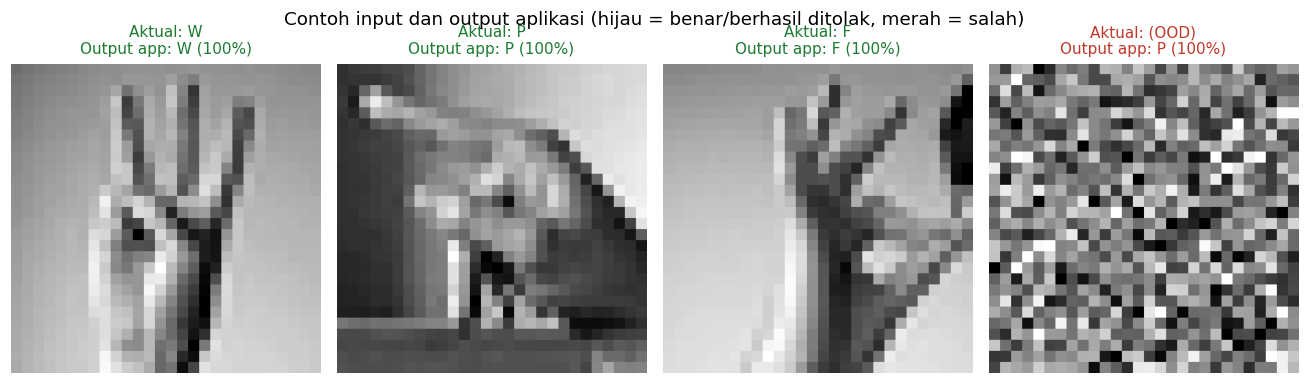

In [62]:
# Uji skrip inferensi deployment di Colab: hasilnya harus sama dengan model Keras
import importlib
sys.path.insert(0, DEPLOY_DIR)
import inference as deploy_inference
importlib.reload(deploy_inference)
clf_deploy = deploy_inference.SignClassifier(os.path.join(DEPLOY_DIR, "config.json"))

N_CEK = 1000
pred_deploy = np.array([CLASS_NAMES.index(clf_deploy.predict(X_te_raw[i])["label"]) for i in range(N_CEK)])
agree = float((pred_deploy == pred_te[:N_CEK]).mean())
acc_deploy = float((pred_deploy == y_test[:N_CEK]).mean())
print(f"Kesesuaian prediksi app (TFLite + praproses deploy) vs Keras: {agree*100:.2f}% pada {N_CEK} citra uji")
print(f"Akurasi app pada {N_CEK} citra uji pertama: {acc_deploy*100:.2f}%")

fig, axes = plt.subplots(1, len(EXAMPLES), figsize=(3 * len(EXAMPLES), 3.6))
contoh_hasil = []
for ax, p in zip(np.atleast_1d(axes), EXAMPLES):
    r = clf_deploy.predict(np.array(Image.open(p).convert("RGB")))
    aktual = os.path.basename(p).split("_aktual_")[-1].replace(".png", "") if "_aktual_" in p else "(OOD)"
    contoh_hasil.append({"file": os.path.basename(p), "aktual": aktual, "prediksi": r["label"],
                         "confidence": r["confidence"], "diterima": r["accepted"]})
    ax.imshow(Image.open(p), cmap="gray"); ax.axis("off")
    hasil = f"{r['label']} ({r['confidence']*100:.0f}%)" if r["accepted"] else f"DITOLAK ({r['confidence']*100:.0f}%)"
    benar = (r["accepted"] and r["label"] == aktual) or (aktual == "(OOD)" and not r["accepted"])
    ax.set_title(f"Aktual: {aktual}\nOutput app: {hasil}", fontsize=10, color="#1e7b34" if benar else "#c0392b")
plt.suptitle("Contoh input dan output aplikasi (hijau = benar/berhasil ditolak, merah = salah)", fontsize=12)
plt.tight_layout(); savefig("fig_deploy_contoh"); plt.show()

R["deploy"] = {"variant": DEPLOY_VARIANT, "threshold": TAU, "n_cek": N_CEK, "agreement": agree, "acc_cek": acc_deploy,
               "contoh": contoh_hasil, "files": sorted(os.listdir(DEPLOY_DIR)),
               "model_kb": os.path.getsize(os.path.join(DEPLOY_DIR, "model.tflite")) / 1024}

In [63]:
# (Opsional) Jalankan aplikasi di Colab untuk tangkapan layar/video demo sebelum deploy ke Hugging Face
if RUN_GRADIO_DEMO:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
    cwd_awal = os.getcwd()
    os.chdir(DEPLOY_DIR)
    try:
        import app as deploy_app
        deploy_app.demo.launch(share=True, debug=False)
    finally:
        os.chdir(cwd_awal)
else:
    print("RUN_GRADIO_DEMO=False. Ubah ke True untuk menjalankan aplikasi Gradio di Colab.")

RUN_GRADIO_DEMO=False. Ubah ke True untuk menjalankan aplikasi Gradio di Colab.


## 18. Menyimpan Hasil dan Menyiapkan Repositori GitHub
Disimpan: `results.json`, CSV ringkasan, *classification report*, dan folder `outputs/repo/` yang siap di-*push* ke GitHub. Folder repo berisi `README.md` lengkap (deskripsi, anggota dan peran, hasil, cara menjalankan), `requirements.txt`, berkas deployment, grafik, dan hasil. Notebook ini juga perlu disalin ke folder repo (**File → Download .ipynb**).

In [64]:
R["meta"]["runtime_total_min"] = (time.time() - T_START) / 60
R["meta"]["final_model_path"] = final_path
R["meta"]["links"] = {"github": LINK_GITHUB, "video": LINK_VIDEO, "app": LINK_APP}

def to_json(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(R, f, indent=2, default=to_json)

REPO_DIR = os.path.join(OUT_DIR, "repo")
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)
shutil.copytree(DEPLOY_DIR, os.path.join(REPO_DIR, "deploy"))
shutil.copytree(FIG_DIR, os.path.join(REPO_DIR, "hasil", "figures"))
for fn in ["results.json", "ringkasan_eksperimen.csv", "classification_report_E5.csv"]:
    shutil.copy(os.path.join(OUT_DIR, fn), os.path.join(REPO_DIR, "hasil", fn))
with open(os.path.join(REPO_DIR, "requirements.txt"), "w") as f:
    f.write("tensorflow>=2.16\nkeras>=3\nnumpy\npandas\nscikit-learn\nmatplotlib\nseaborn\nopencv-python\npillow\npython-docx\nkagglehub\n")
with open(os.path.join(REPO_DIR, ".gitignore"), "w") as f:
    f.write("data/\noutputs/logs/\n*.h5\n__pycache__/\n.ipynb_checkpoints/\n")

baris = "\n".join(f"| {a['nim']} | {a['nama']} | {a['peran']} |" for a in ANGGOTA)
hasil_md = "\n".join(f"| {e['id']} | {e['nama']} | {e['params']:,} | {e['test_acc']*100:.2f}% | {e['macro_f1']*100:.2f}% |" for e in R["experiments"])
f1t, v2 = R["fitur1"]["test"], R["fitur2"]["varian"][DEPLOY_VARIANT]
readme = (f"# {JUDUL}\n\n"
          f"Proyek **{MATA_KULIAH}**, Universitas Mikroskil, Semester {SEMESTER} TA {TAHUN_AJARAN}. Kelompok **{NAMA_KELOMPOK}** ({KELAS}).\n\n"
          "Model DNN (MLP) dan CNN untuk mengklasifikasikan 24 huruf statis American Sign Language dari citra 28×28 "
          "(dataset [Sign Language MNIST](https://www.kaggle.com/datasets/datamunge/sign-language-mnist)).\n\n"
          f"- Aplikasi: {LINK_APP or '(isi link Hugging Face Space)'}\n- Video demo: {LINK_VIDEO or '(isi link video)'}\n\n"
          "## Anggota dan peran\n| NIM | Nama | Peran |\n|---|---|---|\n" + baris + "\n\n"
          "## Hasil (data uji resmi, 7.172 citra)\n| ID | Model | Parameter | Akurasi | Macro-F1 |\n|---|---|---|---|---|\n" + hasil_md + "\n\n"
          f"**Fitur unik 1 (ambang confidence τ = {TAU:.2f})**: akurasi prediksi yang diterima {f1t['acc_diterima']*100:.2f}% "
          f"dengan coverage {f1t['coverage']*100:.2f}%.\n\n"
          f"**Fitur unik 2 (TFLite {DEPLOY_VARIANT})**: {v2['size_kb']:.0f} KB (Keras {R['fitur2']['keras']['size_kb']:.0f} KB), "
          f"akurasi {v2['test_acc']*100:.2f}%.\n\n"
          "## Cara menjalankan\n### Training dan evaluasi (Google Colab)\n"
          "1. Buka notebook `.ipynb` di Google Colab, lalu pilih Runtime → T4 GPU.\n"
          "2. Isi sel KONFIGURASI, lalu Runtime → Run all.\n\n"
          "### Aplikasi secara lokal\n```bash\ncd deploy\npip install -r requirements.txt gradio\npython app.py\n```\n\n"
          "## Struktur\n```\n├── <notebook>.ipynb      # source code lengkap\n├── deploy/                # aplikasi Gradio (HF Spaces)\n"
          "├── hasil/                 # grafik, results.json, ringkasan eksperimen\n└── requirements.txt\n```\n")
with open(os.path.join(REPO_DIR, "README.md"), "w") as f:
    f.write(readme)
shutil.copy(os.path.join(REPO_DIR, "README.md"), os.path.join(OUT_DIR, "README.md"))
print("results.json, README.md, dan folder repo siap. Total waktu run:", f"{R['meta']['runtime_total_min']:.1f} menit")

results.json, README.md, dan folder repo siap. Total waktu run: 12.2 menit


**(Opsional) TensorBoard**: hapus tanda `#` lalu jalankan sel berikut untuk melihat kurva training secara interaktif.

In [65]:
# %load_ext tensorboard
# %tensorboard --logdir outputs/logs/tensorboard